# Phase 20 — Shared Four-Domain Global Baseline (single frozen UNet++)

**Stage B: Multi-Domain Scaling — first scientific training phase**

**Project:** RA-MedFiLM-Seg++ (Regional Scale-Aware Feature Interleaving Multi-Domain Medical Segmentation)
**Target venue:** Q1 / A* peer-reviewed medical computer vision

---

## 1. Title / scope / governance

| Item | Value |
|---|---|
| Phase | 20 |
| Stage | Stage B: Multi-Domain Scaling |
| Title | Shared Multi-Domain Global Baseline |
| Architecture | **UNet++** (one shared parameter set, no FiLM, no regional module) |
| Experiment | `phase20_shared_unetpp_fourdomain_seed42_clean_v3` |
| Domains | ISIC (0), BUSI (1), KVASIR (2), KUB (3) |
| Manifest | `manifests/phase4_v3` (CANONICAL_ACTIVE_DEVELOPMENT) |
| Cohorts read | TRAIN and VAL only |
| TEST | `CLOSED` — 0 image reads, 0 mask reads, 0 inference, 0 visualizations |
| Model training in this phase | **YES — exactly one logical run** |

**Explicitly excluded from this phase:** FiLM, task embeddings, domain embeddings, any
regional mechanism, the Phase-13/H3 localizer, the Phase-14 refiner, Oracle ROIs,
proposal heatmaps, regional crops, routing, dataset-specific decoders or heads.
`task_id` is used for **sampling and reporting only** and is never a model input.

In [1]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

pd.set_option("display.width", 260)
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 400)


def find_root():
    """Repository-root discovery that does not depend on one shell, OS or hardcoded path."""
    p = Path.cwd()
    for _ in range(6):
        if (p / "manifests").is_dir() and (p / "reports").is_dir() and (p / "src").is_dir():
            return p
        p = p.parent
    return Path("D:/Softfors/jup")


ROOT = find_root()
AUD = ROOT / "reports/audits"
TAB = ROOT / "reports/tables"
FIG = ROOT / "reports/figures/phase20_multidomain_baseline"
EXP_ID = "phase20_shared_unetpp_fourdomain_seed42_clean_v3"
EXP = ROOT / "experiments" / EXP_ID
CKP = ROOT / "checkpoints" / EXP_ID


def sha256_file(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def jload(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


print("ROOT:", ROOT)
print("experiment:", EXP_ID)

ROOT: D:\Softfors\jup
experiment: phase20_shared_unetpp_fourdomain_seed42_clean_v3


## 2. Phase-19 handoff

Phase 19 completed the prospective four-domain harmonization preparation. Phase 20
inherits its frozen contracts rather than re-deriving them. Every inherited artifact is
SHA-bound below, and the four-domain task mapping and development populations are
re-asserted from the manifests.

In [2]:
AUTHORITY = {
    "stage_b_authorization": "reports/audits/stage_b_phase19_authorization.json",
    "stage_b_governance_state": "reports/audits/stage_b_governance_state.json",
    "phase19_protocol": "reports/audits/phase19_multidomain_harmonization_protocol.json",
    "phase19_task_id_registry": "reports/tables/phase19_task_id_registry.csv",
    "phase19_harmonized_schema": "reports/tables/phase19_harmonized_schema.csv",
    "phase19_phase20_entry_criteria": "reports/tables/phase19_phase20_entry_criteria.csv",
    "phase19_preprocessing_contract": "reports/audits/phase19_preprocessing_contract.json",
    "phase19_evaluation_contract": "reports/audits/phase19_evaluation_contract.json",
    "phase19_legacy_evidence_reuse_map": "reports/audits/phase19_legacy_evidence_reuse_map.json",
    "phase19_leakage_safeguards": "reports/audits/phase19_leakage_safeguards.json",
    "phase19_loader_smoke_test": "reports/audits/phase19_loader_smoke_test.json",
}
auth_rows = [{"artifact": k, "path": v, "sha256": sha256_file(ROOT / v)[:32] + "…"}
             for k, v in AUTHORITY.items()]
display(pd.DataFrame(auth_rows))

binding = jload(AUD / "phase20_phase19_authority_binding.json")
print("authority checks all passed:", binding["all_checks_passed"])
display(pd.DataFrame(sorted(binding["checks"].items()), columns=["check", "pass"]))
display(pd.DataFrame([binding["observed_task_id_registry"]]).T.rename(columns={0: "task_id"}))
display(pd.DataFrame(binding["observed_populations"]["TRAIN"], index=["TRAIN n"]).T
        .join(pd.DataFrame(binding["observed_populations"]["VAL"], index=["VAL n"]).T))

,artifact,path,sha256
0,stage_b_authorization,reports/audits/stage_b_phase19_authorization.json,44322100cd63aedc451408706db1aaa3…
1,stage_b_governance_state,reports/audits/stage_b_governance_state.json,109112a9e947e6533e880fc9983c1677…
2,phase19_protocol,reports/audits/phase19_multidomain_harmonizati...,ab8289a26fbd9946a49bc3fe89c9d875…
3,phase19_task_id_registry,reports/tables/phase19_task_id_registry.csv,d1fed41c5b38c8e08798ac5adbfa427c…
4,phase19_harmonized_schema,reports/tables/phase19_harmonized_schema.csv,c64d4c434c4692214da87aaf7bb4803c…
5,phase19_phase20_entry_criteria,reports/tables/phase19_phase20_entry_criteria.csv,5d37811ce4d9392b37d516368e5a289c…
6,phase19_preprocessing_contract,reports/audits/phase19_preprocessing_contract....,a1db4b083611bc5a6ec4928427c77fcc…
7,phase19_evaluation_contract,reports/audits/phase19_evaluation_contract.json,7f7f18fc17e1f377ef8fefcd9f4c9280…
8,phase19_legacy_evidence_reuse_map,reports/audits/phase19_legacy_evidence_reuse_m...,415eeedea6f9f7f1590dcf3e9dbaf4ee…
9,phase19_leakage_safeguards,reports/audits/phase19_leakage_safeguards.json,b41307eb5c36401e7882f217e953163f…


authority checks all passed: True


,check,pass
0,authority_artifacts_present,True
1,authorization_status_authorized,True
2,four_domains_present_in_both_splits,True
3,loader_smoke_test_passed,True
4,manifest_task_ids_match_expected,True
5,task_id_registry_manifest_agrees_flag,True
6,task_id_registry_matches_expected,True
7,train_population_matches,True
8,val_population_matches,True


,task_id
ISIC,0
BUSI,1
KVASIR,2
KUB,3


,TRAIN n,VAL n
BUSI,602,84
ISIC,2556,357
KUB,1978,280
KVASIR,696,87


## 3. Phase-20 scientific question

> **How well can ONE shared conventional segmentation model represent all four medical
> domains under the harmonized Stage-B data contract, WITHOUT task-conditioned FiLM and
> WITHOUT the regional mechanism?**

This baseline is the **prospective reference** for Phase 21 (Global MedFiLM). Phase 21
will ask whether task-conditioned FiLM improves *this* baseline. Phase 20 does **not**
attempt to prove MedFiLM and does **not** compare against Phase-21 results, which do not
exist yet. Keeping that causal comparison clean is the point of freezing this phase first.

## 4. Legacy baseline evidence review

Historical conventional baselines that actually exist in the tested projects. Every value
below is labelled **`LEGACY_PRIOR_EVIDENCE__NOT_CURRENT_PHASE20_RESULT`** and must never
be compared numerically against Phase-20 results.

In [3]:
legacy = jload(AUD / "phase20_legacy_baseline_selection_evidence.json")
print("evidence label:", legacy["evidence_label"])
print()
print("Finding — legacy KUB-bearing shared baseline:",
      legacy["finding_no_legacy_four_domain_shared_baseline"]["kub_bearing_shared_baseline_found"])
display(Markdown(legacy["finding_no_legacy_four_domain_shared_baseline"]["statement"]))

comp = legacy["same_repository_clean_v3_conventional_comparison"]
display(Markdown(f"**Same-repository clean-v3 conventional comparison** — {comp['scope']}"))
display(pd.DataFrame(comp["results"])[["architecture", "experiment_id", "params",
                                       "best_epoch", "best_val_macro_dice",
                                       "final_epoch", "stop_reason"]])
print("ranking:", comp["ranking_by_best_val_macro_dice"])
print("strongest:", comp["strongest"], "=", comp["strongest_value"],
      "| margin over next:", comp["margin_over_next"])
display(Markdown("**Legacy multi-domain projects**"))
display(pd.DataFrame(legacy["legacy_projects"])[
    ["project", "domain_count", "includes_kub", "baselines",
     "implementation_availability", "reuse_recommendation"]])

evidence label: LEGACY_PRIOR_EVIDENCE__NOT_CURRENT_PHASE20_RESULT

Finding — legacy KUB-bearing shared baseline: False


No legacy tested project trained a single shared model across a KUB-bearing four-domain pool. The legacy shared multi-domain baselines are three-domain (ISIC/BUSI/Kvasir) at 256 px (medfilm_seg) or weak-label at 384 px (medfilm_seg_v2, DO_NOT_REUSE).

**Same-repository clean-v3 conventional comparison** — KUB only, phase4_v3, 512 px, identical loss/optimizer/scheduler/selection protocol across all four architectures

,architecture,experiment_id,params,best_epoch,best_val_macro_dice,final_epoch,stop_reason
0,U-Net,phase9_kub_unet_baseline_seed42_512_clean_v3,7763041,44,0.740613,59,EARLY_STOP
1,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,7851285,54,0.752513,69,EARLY_STOP
2,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,9159681,70,0.764160,85,EARLY_STOP
3,"DeepLabV3+ (ResNet-50, no pretrained weights)",phase10_kub_deeplabv3plus_seed42_512_clean_v3,40347041,52,0.750914,67,EARLY_STOP


ranking: ['UNet++', 'Attention U-Net', 'DeepLabV3+ (ResNet-50, no pretrained weights)', 'U-Net']
strongest: UNet++ = 0.7641595156062713 | margin over next: 0.01164653


**Legacy multi-domain projects**

,project,domain_count,includes_kub,baselines,implementation_availability,reuse_recommendation
0,final/medfilm_seg,3,False,"[unet, attention_unet]",PARTIAL — the legacy src/models tree is empty ...,REFERENCE_ONLY for hyperparameter shape; hyper...
1,final/medfilm_seg_v2,3,False,"[plain_weak_segmentation, attention_unet_weak_...",YES — final/medfilm_seg_v2/src_v2/models_v2/at...,DO_NOT_REUSE (Phase-19 legacy reuse map: scien...
2,Omni_segv2,5,False,[multi-domain 2.5D/3D stream],REFERENCE_ONLY,REFERENCE_ONLY (naming/modality vocabulary only)
3,safeseg,4,False,[notebook-level experiments],REFERENCE_ONLY,REFERENCE_ONLY


## 5. Why ONE baseline instead of repeating five

The user's tested projects already contain extensive four-domain baseline experiments. The
task is therefore to **freeze one strong conventional baseline**, not to re-run an
architecture sweep. Repeating a five-model current experiment would spend hours confirming
what the legacy work already established, and would delay the Phase-21 reference.

The selection uses prior evidence only. `current_phase20_results_used_for_selection` is
`false`, and the freeze is verified below to predate training.

## 6. Architecture freeze

In [4]:
freeze = jload(AUD / "phase20_baseline_architecture_freeze.json")
display(pd.DataFrame([
    {"field": "frozen_architecture", "value": freeze["frozen_architecture"]},
    {"field": "repository_implementation", "value": freeze["repository_implementation"]},
    {"field": "architecture_descriptor", "value": freeze["architecture_descriptor"]},
    {"field": "selection_basis", "value": freeze["selection_basis"]},
    {"field": "selection_time", "value": freeze["selection_time"]},
    {"field": "current_phase20_results_used_for_selection",
     "value": freeze["current_phase20_results_used_for_selection"]},
    {"field": "evidence_label", "value": freeze["selection_evidence_summary"]["evidence_label"]},
]))
display(pd.DataFrame([{"forbidden module": m, "present": p}
                      for m, p in zip(freeze["model_contract"]["forbidden_modules"],
                                      freeze["model_contract"]["forbidden_modules_present"])]))
display(Markdown("**Rationale**"))
for r in freeze["rationale"]:
    display(Markdown(f"- {r}"))
assert freeze["selection_time"] == "PRE_TRAINING"
assert freeze["current_phase20_results_used_for_selection"] is False
assert freeze["model_contract"]["forbidden_modules_present"] == []

,field,value
0,frozen_architecture,UNet++
1,repository_implementation,src/models/unetpp.py
2,architecture_descriptor,unetpp_nested_4_level_no_deep_supervision_base32
3,selection_basis,LEGACY_TESTED_PROJECT_PRIOR_EVIDENCE
4,selection_time,PRE_TRAINING
5,current_phase20_results_used_for_selection,False
6,evidence_label,LEGACY_PRIOR_EVIDENCE__NOT_CURRENT_PHASE20_RESULT


""


**Rationale**

- Already implemented and tested in this repository (src/models/unetpp.py, Phase-10 clean-v3).

- Strongest conventional clean-v3 architecture in the repository under a fixed protocol (best VAL macro Dice 0.764160 vs 0.752513 / 0.750914 / 0.740613).

- Compatible with binary segmentation and a single 1-channel output head.

- Requires no FiLM and no regional module, so it is a clean image-only reference for Phase 21.

## 7. Cross-domain duplicate audit

Phase 19 explicitly left one issue unresolved: cross-domain near-duplicate detection across
the newly combined four-domain pool. Phase 20 resolves it **before** training, using TRAIN
and VAL image content only.

Method: exact `sha256` of the raw image bytes, plus the **already-approved repository**
perceptual hash (32x32 L, 2-D DCT, top-left 8x8, median threshold, 64-bit) with the frozen
Hamming distance <= 6 candidate threshold.

**Blocking rule (declared before interpretation):** block training if ANY TRAIN<->VAL pair
is identical by content sha256 or at Hamming distance 0.

In [5]:
dup = jload(AUD / "phase20_cross_domain_duplicate_audit.json")
print("verdict:", dup["verdict"])
print("pairs compared:", dup["populations"]["compared_pairs"])
print("candidate pairs:", dup["n_candidate_pairs"],
      "| blocking pairs:", dup["n_blocking_pairs"],
      "| exact sha matches:", dup["n_exact_content_sha_matches_train_val"],
      "| high-attention:", dup["candidates_high_attention"])
rows = []
for pair, v in dup["train_val_pairwise"].items():
    rows.append({"pair": pair, "kind": v["kind"], "pairs_compared": v["n_pairs_compared"],
                 "d=0": v["n_hamming_0"], "d1-2": v["n_hamming_1_2"],
                 "d3-4": v["n_hamming_3_4"], "d5-6": v["n_hamming_5_6"],
                 "min_hamming": v["min_hamming"]})
display(pd.DataFrame(rows))
display(Markdown("**Within-split descriptive duplicate counts**"))
display(pd.DataFrame(dup["within_split"]))
cand = pd.read_csv(TAB / "phase20_cross_domain_duplicate_candidates.csv")
if len(cand):
    display(Markdown(f"Candidate pairs ({len(cand)}), all within-dataset, all reported only:"))
    display(cand[["dataset_train", "dataset_val", "pair_kind", "hamming_distance",
                  "classification", "same_patient_id"]].head(40))
assert dup["training_may_start"] is True
assert dup["n_blocking_pairs"] == 0

verdict: PHASE20_DUPLICATE_AUDIT_PASS__NO_TRAIN_VAL_LEAKAGE
pairs compared: 4712256
candidate pairs: 37 | blocking pairs: 0 | exact sha matches: 0 | high-attention: 0


,pair,kind,pairs_compared,d=0,d1-2,d3-4,d5-6,min_hamming
0,ISIC<->ISIC,WITHIN_DATASET,912492,0,0,10,19,4
1,ISIC<->KVASIR,CROSS_DATASET,470844,0,0,0,0,10
2,ISIC<->KUB,CROSS_DATASET,1421826,0,0,0,0,10
3,BUSI<->ISIC,CROSS_DATASET,429618,0,0,0,0,12
4,BUSI<->BUSI,WITHIN_DATASET,50568,0,0,0,0,12
5,BUSI<->KVASIR,CROSS_DATASET,110838,0,0,0,0,14
6,BUSI<->KUB,CROSS_DATASET,334712,0,0,0,0,12
7,KVASIR<->KVASIR,WITHIN_DATASET,60552,0,0,1,5,4
8,KUB<->KVASIR,CROSS_DATASET,366966,0,0,0,0,12
9,KUB<->KUB,WITHIN_DATASET,553840,0,0,1,1,4


**Within-split descriptive duplicate counts**

,split,n_images,n_pairs_compared,n_hamming_0,n_hamming_1_2,n_hamming_3_4,n_hamming_5_6
0,TRAIN,5832,17003196,39,43,79,189
1,VAL,808,326028,1,0,0,5


Candidate pairs (37), all within-dataset, all reported only:

,dataset_train,dataset_val,pair_kind,hamming_distance,classification,same_patient_id
0,ISIC,ISIC,WITHIN_DATASET,4,POSSIBLE_NEAR_DUPLICATE,True
1,ISIC,ISIC,WITHIN_DATASET,4,POSSIBLE_NEAR_DUPLICATE,True
2,ISIC,ISIC,WITHIN_DATASET,4,POSSIBLE_NEAR_DUPLICATE,True
3,ISIC,ISIC,WITHIN_DATASET,4,POSSIBLE_NEAR_DUPLICATE,True
4,ISIC,ISIC,WITHIN_DATASET,4,POSSIBLE_NEAR_DUPLICATE,True
5,ISIC,ISIC,WITHIN_DATASET,4,POSSIBLE_NEAR_DUPLICATE,True
6,ISIC,ISIC,WITHIN_DATASET,4,POSSIBLE_NEAR_DUPLICATE,True
7,ISIC,ISIC,WITHIN_DATASET,4,POSSIBLE_NEAR_DUPLICATE,True
8,ISIC,ISIC,WITHIN_DATASET,4,POSSIBLE_NEAR_DUPLICATE,True
9,ISIC,ISIC,WITHIN_DATASET,4,POSSIBLE_NEAR_DUPLICATE,True


## 8. Phase-20 entry gate

Every Phase-19 Phase-20 entry criterion is evaluated independently against authoritative
artifacts rather than trusted from the Phase-19 `met` column alone.

In [6]:
gate = jload(AUD / "phase20_entry_gate.json")
display(pd.DataFrame(gate["criteria"])[
    ["criterion_id", "criterion", "verdict", "blocking", "observed_state"]])
print("entry gate verdict:", gate["phase20_entry_gate_verdict"],
      "| hard fails:", gate["hard_fail_ids"])
print("residual criteria resolved by the Phase-20 audit:",
      gate["residual_criteria_resolved_by_phase20"])
pre = jload(AUD / "phase20_pre_execution_check.json")
print()
print("pre-execution check:", f"{pre['n_passed']}/{pre['n_checks']} PASS",
      "| training authorized:", pre["training_authorized"])
display(pd.DataFrame([{"check": k, **v} for k, v in pre["checks"].items()]))
assert gate["phase20_entry_gate_verdict"] == "PASS"
assert pre["all_checks_passed"] is True

,criterion_id,criterion,verdict,blocking,observed_state
0,E1,All four domains mapped,PASS,True,"['BUSI', 'ISIC', 'KUB', 'KVASIR'] present in T..."
1,E2,No unresolved label-semantic conflict,PASS,True,foreground = (mask > 0) via src.utils.targets....
2,E3,Task IDs frozen,PASS,True,"registry == {'ISIC': 0, 'BUSI': 1, 'KVASIR': 2..."
3,E4,Preprocessing frozen,PASS,True,phase19_preprocessing_contract_v1 FROZEN_FOR_P...
4,E5,Mask semantics frozen,PASS,True,"binary foreground, NEAREST mask interpolation,..."
5,E6,Metadata policy frozen,PASS,True,every metadata field classified exactly once (...
6,E7,TRAIN/VAL loaders smoke-tested,PASS,True,all_checks_passed = True; test_rejected_by_dat...
7,E8,No TEST reads,PASS,True,"test_image_reads = 0, test_mask_reads = 0, tes..."
8,E9,Harmonized batch schema validated,PASS,True,"image (B,C,S,S), mask (B,1,S,S), task_id prese..."
9,E10,No duplicate/leakage blocker,PASS_PHASE19__RESOLVED_BY_PHASE20_AUDIT,True,"phase4_v3 remediation holds (quarantined 118, ..."


entry gate verdict: PASS | hard fails: []
residual criteria resolved by the Phase-20 audit: ['E10']

pre-execution check: 26/26 PASS | training authorized: True


,check,expected,observed,pass
0,phase20_entry_gate_pass,PASS,PASS,True
1,duplicate_audit_pass,PHASE20_DUPLICATE_AUDIT_PASS__NO_TRAIN_VAL_LEA...,verdict=PHASE20_DUPLICATE_AUDIT_PASS__NO_TRAIN...,True
2,phase19_authority_bound,True,True,True
3,train_population_5832,5832,5832,True
4,val_population_808,808,808,True
5,four_domains_present,"[BUSI, ISIC, KUB, KVASIR]","TRAIN=['BUSI', 'ISIC', 'KUB', 'KVASIR'] VAL=['...",True
6,task_ids_match_phase19,"{'ISIC': 0, 'BUSI': 1, 'KVASIR': 2, 'KUB': 3}","{'BUSI': 1, 'ISIC': 0, 'KUB': 3, 'KVASIR': 2}",True
7,test_lock_verified,1683,count=1683,True
8,test_rejected_by_dataset,True,True,True
9,test_rejected_by_loader,True,True,True


## 9. Dataset populations

In [7]:
protocol = jload(AUD / "phase20_shared_global_baseline_protocol.json")
pops = protocol["dataset_populations"]
pop_df = pd.DataFrame({
    "TRAIN": pops["TRAIN"], "VAL": pops["VAL"],
})
pop_df.loc["TOTAL"] = [pops["TRAIN_total"], pops["VAL_total"]]
pop_df["TRAIN_share"] = (pop_df["TRAIN"] / pops["TRAIN_total"]).round(4)
display(pop_df)
display(pd.DataFrame([pops["task_ids"]]).T.rename(columns={0: "task_id"}))
print("protocol status:", protocol["status"])

,TRAIN,VAL,TRAIN_share
BUSI,602,84,0.1032
ISIC,2556,357,0.4383
KUB,1978,280,0.3392
KVASIR,696,87,0.1193
TOTAL,5832,808,1.0000


,task_id
ISIC,0
BUSI,1
KVASIR,2
KUB,3


protocol status: PHASE20_PROTOCOL_FROZEN__AWAITING_EXECUTION


## 10. Input / preprocessing contract

Phase 19 preserved both deterministic 1-channel and 3-channel converters, deferring the
architecture-wide decision to Phase 24. For Phase 20 only, an **operational** baseline
input contract is frozen: **3-channel** input, labelled
`PHASE20_BASELINE_OPERATIONAL_INPUT_ONLY`. It is **not** the final Phase-24 policy.

In [8]:
pre_c = jload(AUD / "phase19_preprocessing_contract.json")
display(pd.DataFrame([
    {"item": "channel_policy", "value": protocol["input_representation"]["channel_policy"]},
    {"item": "contract label", "value": protocol["input_representation"]["contract_label"]},
    {"item": "not final Phase-24 policy",
     "value": protocol["input_representation"]["not_the_final_phase24_policy"]},
    {"item": "input_resolution", "value": protocol["input_resolution"]},
    {"item": "spatial policy", "value": pre_c["spatial"]["policy"]},
    {"item": "scale formula", "value": pre_c["spatial"]["scale_formula"]},
    {"item": "image resample", "value": pre_c["spatial"]["image_resample"]},
    {"item": "mask resample", "value": pre_c["spatial"]["mask_resample"]},
    {"item": "foreground rule", "value": pre_c["mask"]["foreground_rule"]},
    {"item": "intensity normalization", "value": pre_c["image"]["intensity_normalization"]},
]))
display(Markdown("**Model input excludes** (governance):"))
display(pd.DataFrame({"excluded from model input":
                      protocol["input_representation"]["model_input_excludes"]}))
display(Markdown("**Resolution decision**"))
display(pd.DataFrame([{"frozen": protocol["resolution_decision"]["frozen"],
                       "decision_time": protocol["resolution_decision"]["decision_time"],
                       "no_resolution_search": protocol["resolution_decision"]["no_resolution_search"]}]))
for e in protocol["resolution_decision"]["evidence"]:
    display(Markdown(f"- {e}"))

,item,value
0,channel_policy,RGB_3CH
1,contract label,PHASE20_BASELINE_OPERATIONAL_INPUT_ONLY
2,not final Phase-24 policy,True
3,input_resolution,512
4,spatial policy,aspect-preserving resize + centre pad
5,scale formula,"scale = min(size / w, size / h)"
6,image resample,BILINEAR
7,mask resample,NEAREST
8,foreground rule,mask > 0 (src.utils.targets.binarize_mask)
9,intensity normalization,"divide by 255.0 -> [0,1]"


**Model input excludes** (governance):

,excluded from model input
0,task_id
1,dataset_id
2,KUB category
3,patient_id
4,case_id
5,foreground_fraction
6,mask-derived metadata


**Resolution decision**

,frozen,decision_time,no_resolution_search
0,512,PRE_TRAINING,True


- No legacy KUB-bearing four-domain shared baseline exists (reports/audits/phase20_legacy_baseline_selection_evidence.json).

- The legacy fully-supervised shared three-domain baseline used 256 px (medfilm_seg) but belongs to a superseded pipeline whose hyperparameters the Phase-19 reuse map explicitly does NOT adopt.

- The frozen architecture's own repository clean-v3 evidence (Phase-10 UNet++) was obtained at 512 px.

- 512 is the Phase-19 preprocessing default_size and preserves KUB tiny-object detail, which is the project's central difficulty.

- A throughput probe (execution mechanism only) confirmed 512 px at batch 4 with 4 loader workers costs ~7.3 min/epoch against ~7.0 min/epoch of GPU time, so 512 is operationally affordable.

## 11. Domain-balanced sampling

TRAIN is strongly imbalanced: ISIC 2556 (43.8%), KUB 1978 (33.9%), KVASIR 696 (11.9%),
BUSI 602 (10.3%). ISIC alone is 4.2x BUSI. A plain shuffle would let ISIC and KUB dominate.
Phase 20 freezes a **domain-balanced** weighted sampler so each domain contributes an equal
expected share of every epoch.

`task_id` / `dataset` are used for **sampling only** and are never fed to the network.

In [9]:
samp = jload(AUD / "phase20_sampling_policy_audit.json")
print("policy:", samp["policy_id"])
print(samp["policy"])
rows = []
for d, v in samp["expected_balanced_proportions"].items():
    e = samp["empirical_check"]["per_domain"][d]
    rows.append({"dataset": d, "pool_size": v["dataset_size"],
                 "pool_share": v["dataset_share_of_pool"],
                 "expected_sampling_proportion": v["expected_sampling_proportion"],
                 "empirical_proportion": e["proportion"], "empirical_count": e["count"]})
display(pd.DataFrame(rows))
display(Markdown(f"Effect: {samp['effect']}"))
print("governance:", samp["governance"])

policy: phase20_domain_balanced_uniform_v1
WeightedRandomSampler with per-sample weight 1/n_domain, num_samples = len(TRAIN) = 5832, replacement = True


,dataset,pool_size,pool_share,expected_sampling_proportion,empirical_proportion,empirical_count
0,BUSI,602,0.103224,0.25,0.256344,1495
1,ISIC,2556,0.438272,0.25,0.241084,1406
2,KUB,1978,0.339163,0.25,0.241770,1410
3,KVASIR,696,0.119342,0.25,0.260802,1521


Effect: each domain contributes ~25% of the sampled batches instead of ISIC 43.8% / KUB 33.9% / KVASIR 11.9% / BUSI 10.3%

governance: {'task_id_used_for_sampling_only': True, 'task_id_passed_to_model_forward': False, 'dataset_used_for_bookkeeping_only': True}


## 12. Model architecture

One shared parameter set across all four domains. Single 1-channel binary logit output.

In [10]:
from src.models.unetpp import UNetPlusPlus

model = UNetPlusPlus(in_channels=3, out_channels=1, base_channels=32)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"UNetPlusPlus params = {n_params:,} | in_channels=3 | out_channels=1 | base_channels=32")
mods = dict(model.named_modules())
forbidden = [n for n in mods
             if any(k in n.lower() for k in ("film", "localizer", "proposal", "roi",
                                             "regional", "task_embed", "domain_embed", "routing"))]
print("forbidden modules present:", forbidden)
print("output head:", model.head)
print("shared across domains:", True, "| one parameter set:", True)
assert not forbidden
assert model.head.out_channels == 1

UNetPlusPlus params = 9,159,681 | in_channels=3 | out_channels=1 | base_channels=32
forbidden modules present: []
output head: Conv2d(32, 1, kernel_size=(1, 1), stride=(1, 1))
shared across domains: True | one parameter set: True


## 13. Training configuration (frozen before training)

The configuration reuses the proven conventional clean-v3 training contract already
verified in this repository (Phase 9 / Phase 10 configs) rather than inventing new values.
No loss / optimizer / LR / scheduler sweep, no second seed.

In [11]:
cfg_rows = [
    ("experiment_id", protocol["experiment_id"]),
    ("architecture", protocol["architecture"]),
    ("input channel policy", protocol["input_representation"]["channel_policy"]),
    ("input resolution", protocol["input_resolution"]),
    ("loss", f"{protocol['loss']['name']} (bce {protocol['loss']['bce_weight']} / "
             f"dice {protocol['loss']['dice_weight']}, eps {protocol['loss']['dice_epsilon']})"),
    ("optimizer", f"{protocol['optimizer']['name']} lr={protocol['learning_rate']} "
                  f"wd={protocol['weight_decay']}"),
    ("scheduler", f"{protocol['scheduler']['name']} T_max={protocol['scheduler']['T_max']} "
                  f"({protocol['scheduler']['step']})"),
    ("batch size", protocol["batch_size"]),
    ("eval batch size", protocol["eval_batch_size"]),
    ("num workers", protocol["num_workers"]),
    ("AMP", protocol["amp"]),
    ("seed", protocol["seed"]),
    ("max epochs", protocol["max_epochs"]),
    ("early stopping", f"patience {protocol['early_stopping']['patience']}, "
                       f"ties count as bad = {protocol['early_stopping']['ties_count_as_bad_epochs']}"),
    ("checkpoint metric", protocol["checkpoint_selection"]["metric"]),
    ("checkpoint tie-break", protocol["checkpoint_selection"]["tie_break"]),
    ("threshold", protocol["evaluation_metrics"]["threshold"]),
    ("logical runs authorized", protocol["single_run_authorization"]["logical_runs_authorized"]),
]
display(pd.DataFrame(cfg_rows, columns=["field", "value"]))
display(Markdown("**Code SHAs bound in the protocol**"))
display(pd.DataFrame(sorted(protocol["code_shas"].items(), key=lambda kv: kv[0]),
                     columns=["file", "sha256"]))

,field,value
0,experiment_id,phase20_shared_unetpp_fourdomain_seed42_clean_v3
1,architecture,unetpp_nested_4_level_no_deep_supervision_base32
2,input channel policy,RGB_3CH
3,input resolution,512
4,loss,"bce_dice (bce 0.5 / dice 0.5, eps 1e-06)"
5,optimizer,AdamW lr=0.0001 wd=0.0001
6,scheduler,CosineAnnealingLR T_max=100 (per_epoch_after_t...
7,batch size,4
8,eval batch size,8
9,num workers,4


**Code SHAs bound in the protocol**

,file,sha256
0,scripts/training/train_phase20_shared_unetpp.py,7ba1ed8238c18277d62c47081a1ff2de0fd1a8fa6b9ef6...
1,src/data/domain_balanced_sampler.py,a59782f1aa85882aa6c1f0dddd75a9888ec34ecc1bdbcc...
2,src/data/loaders.py,eb0c1b5d295d3b77b3e9745fcdeb4ff93f985fd7a58fc8...
3,src/data/multidomain_dataset.py,461062e5d6bf564872645c51c4175e69cb6169b729f1e5...
4,src/data/transforms.py,09fcff4887ff8cda4daa215efad1d504d4d61f70982262...
5,src/losses/segmentation.py,2af539bd47a07c966d4a2784f4df7d81bce0620af8ef8e...
6,src/metrics/evaluation_metrics.py,6c515f6f1a495315c79238292c385a082ae8347489130a...
7,src/models/unet.py,62edc8fb481eb02c46c2c64f6e7219254a57d7ba935a4c...
8,src/models/unetpp.py,87adb3f39d72fc4220445eb8a29f4f9a2c1930f98563b0...
9,src/training/phase20_selection.py,99d412361445c10e45f148ba87dfc39b95e9ca51f82b2a...


## 14. COMPLETE epoch table

One row per completed epoch. No epoch row is omitted, and the saved CSV is authoritative.

In [12]:
history = pd.read_csv(EXP / "history.csv")
closure = jload(AUD / "phase20_training_closure.json")
print(f"epoch rows: {len(history)}")
display(history)

epoch rows: 70


,epoch,train_loss,val_loss,macro_domain_dice,val_dice_ISIC,val_dice_BUSI,val_dice_KVASIR,val_dice_KUB,val_iou_ISIC,val_iou_BUSI,val_iou_KVASIR,val_iou_KUB,val_precision_ISIC,val_precision_BUSI,val_precision_KVASIR,val_precision_KUB,val_recall_ISIC,val_recall_BUSI,val_recall_KVASIR,val_recall_KUB,learning_rate,is_new_best,best_epoch_so_far,bad_epochs,epoch_seconds,cumulative_seconds
0,1,0.506824,0.402742,0.538233,0.689777,0.589043,0.426967,0.447147,0.576267,0.454712,0.304401,0.357101,0.747301,0.694413,0.489456,0.450612,0.787124,0.639977,0.570157,0.637324,0.000100,True,1,0,660.816353,662.552963
1,2,0.376780,0.376368,0.542154,0.675635,0.591702,0.441114,0.460165,0.558825,0.468543,0.324520,0.371023,0.680868,0.738537,0.442647,0.467901,0.836086,0.627152,0.626742,0.605342,0.000100,True,2,0,683.680671,1346.774866
2,3,0.328166,0.348097,0.592267,0.727656,0.721241,0.465044,0.455127,0.622704,0.603496,0.346164,0.366560,0.790562,0.832049,0.655592,0.468424,0.787063,0.729485,0.494824,0.607116,0.000100,True,3,0,691.996615,2039.140456
3,4,0.301419,0.321782,0.627600,0.743170,0.753993,0.565114,0.448124,0.634952,0.641891,0.442872,0.363383,0.741396,0.798224,0.680562,0.507479,0.871581,0.816753,0.636246,0.528247,0.000100,True,4,0,656.772556,2696.253822
4,5,0.277918,0.303231,0.623423,0.790339,0.750001,0.501968,0.451382,0.696319,0.640660,0.384137,0.367936,0.872082,0.831895,0.697799,0.580910,0.802078,0.774148,0.533550,0.523902,0.000099,False,4,1,600.278845,3296.832644
5,6,0.266046,0.329371,0.602482,0.757968,0.674828,0.546202,0.430929,0.659330,0.579158,0.425957,0.347592,0.866640,0.911778,0.796731,0.525538,0.751645,0.630031,0.530212,0.536240,0.000099,False,4,2,599.839205,3896.855484
6,7,0.251078,0.285589,0.671088,0.803845,0.793963,0.665952,0.420592,0.714517,0.683023,0.546608,0.338376,0.868425,0.808239,0.763144,0.596667,0.828723,0.849457,0.716391,0.459761,0.000099,True,7,0,602.214172,4499.248610
7,8,0.236722,0.297333,0.647389,0.760570,0.722789,0.679137,0.427059,0.661530,0.623724,0.554508,0.335218,0.803270,0.827947,0.759400,0.532289,0.818435,0.748188,0.737195,0.488050,0.000098,False,7,1,602.277385,5101.830466
8,9,0.231709,0.292469,0.644731,0.798346,0.747299,0.549498,0.483783,0.709092,0.654855,0.430528,0.387479,0.874461,0.872817,0.557891,0.537212,0.818455,0.742102,0.740330,0.572638,0.000098,False,7,2,596.983279,5699.017971
9,10,0.220117,0.287426,0.680200,0.783475,0.779420,0.675718,0.482185,0.686813,0.663672,0.554210,0.388046,0.864518,0.785319,0.835769,0.544930,0.790976,0.849731,0.672464,0.599567,0.000098,True,10,0,609.459400,6308.651624


## 15-21. Training curves, early stopping, timing and best-checkpoint progression

Every curve is also saved under `reports/figures/phase20_multidomain_baseline/` and embedded
here, so the saved PNG is not the only copy.

**loss** — `reports\figures\phase20_multidomain_baseline\fig_train_val_loss.png`

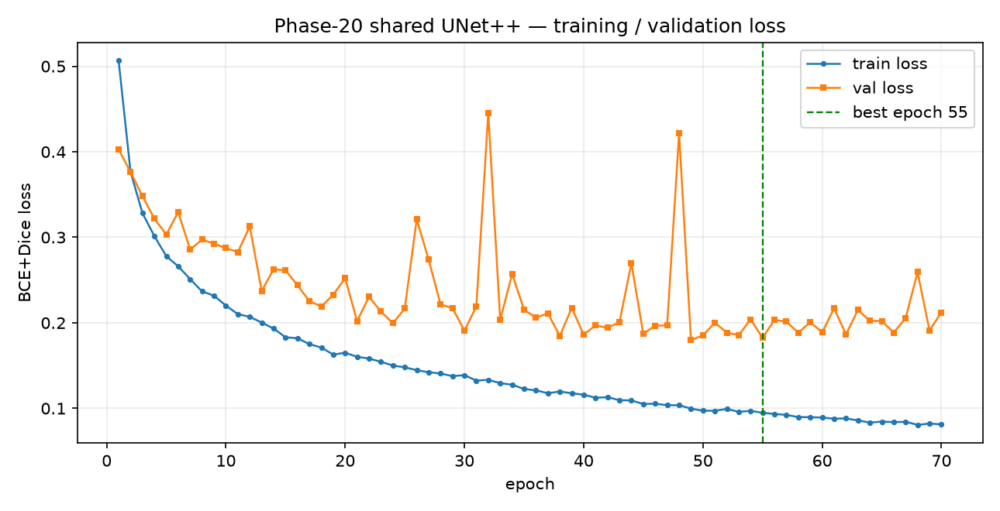

**macro_dice** — `reports\figures\phase20_multidomain_baseline\fig_macro_domain_dice.png`

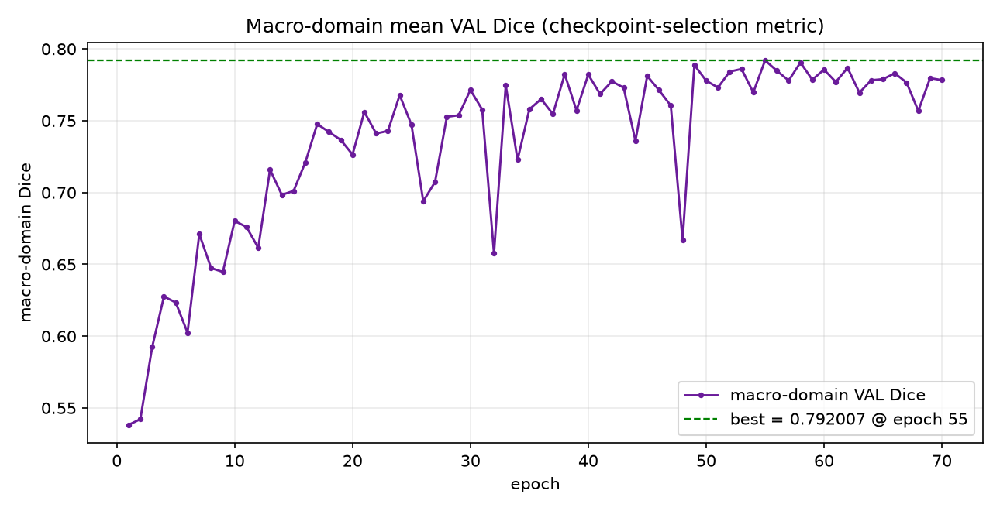

**per_domain_dice** — `reports\figures\phase20_multidomain_baseline\fig_per_domain_dice.png`

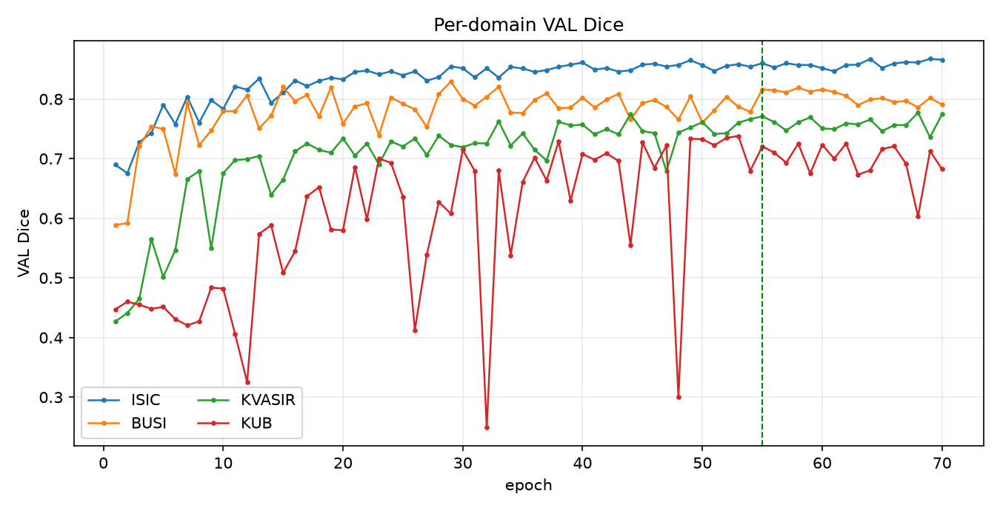

**per_domain_iou** — `reports\figures\phase20_multidomain_baseline\fig_per_domain_iou.png`

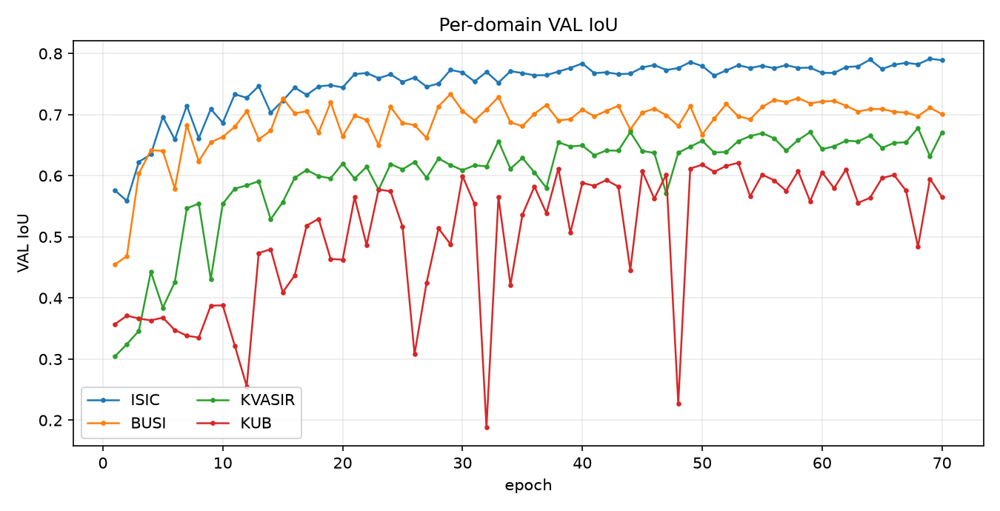

**lr** — `reports\figures\phase20_multidomain_baseline\fig_learning_rate.png`

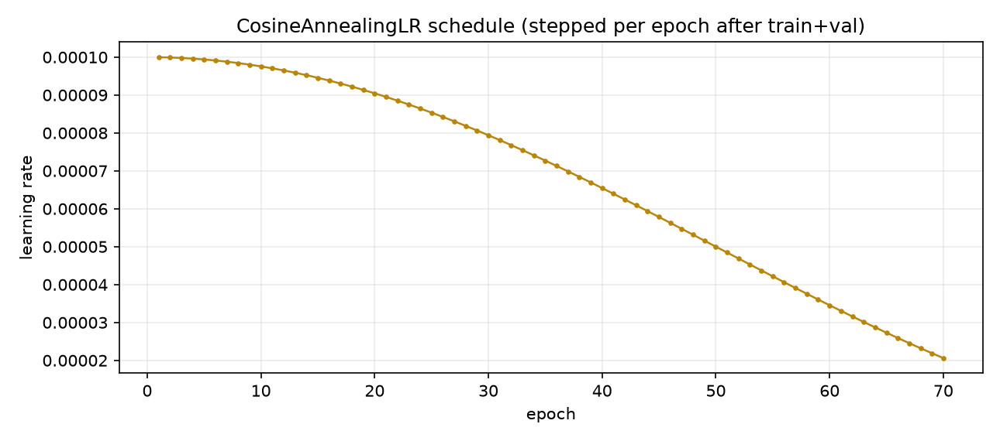

**early_stopping** — `reports\figures\phase20_multidomain_baseline\fig_early_stopping.png`

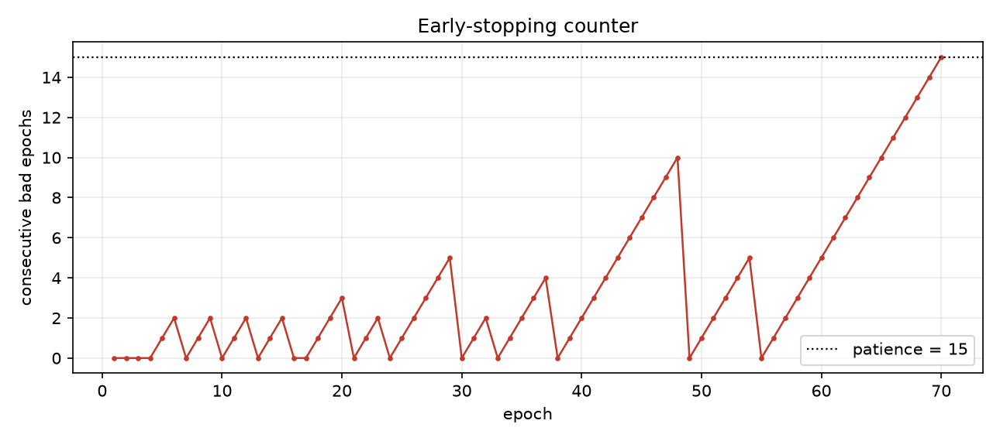

**epoch_seconds** — `reports\figures\phase20_multidomain_baseline\fig_epoch_seconds.png`

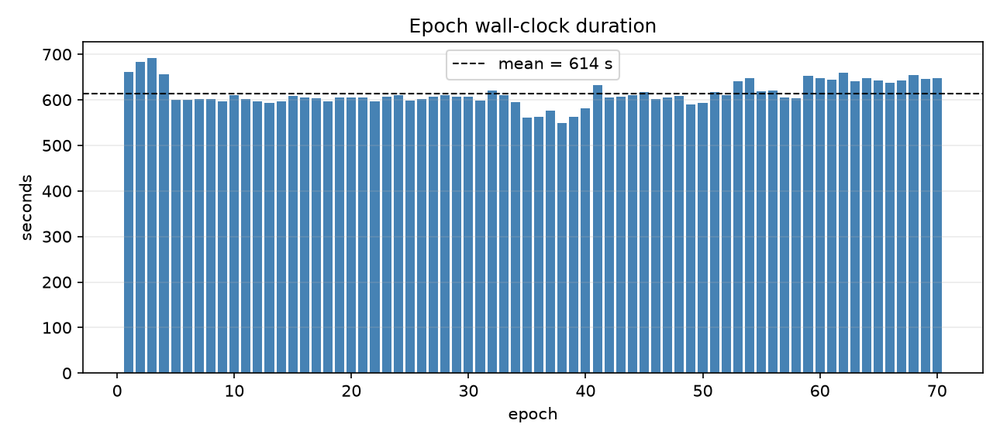

**best_progression** — `reports\figures\phase20_multidomain_baseline\fig_best_progression.png`

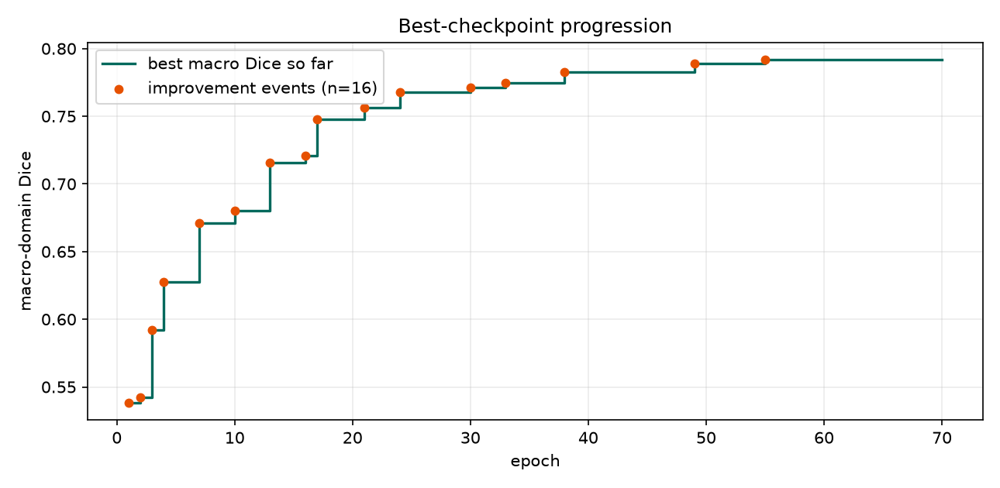

In [13]:
from src.analysis import phase20_baseline as pb

train_figs = pb.build_training_figures(history, closure)
for name, path in train_figs.items():
    display(Markdown(f"**{name}** — `{path.relative_to(ROOT)}`"))
    display(Image(filename=str(path)))

## 22. Resume / interruption history

Durability on this host comes from **resumability**, not detachment: the launching session's
process tree is torn down periodically, so the run is relaunched with `--resume` and continues
the SAME logical run. Resume is bit-exact **by construction** — the data order and every
stochastic augmentation for epoch *k* derive from `derive_epoch_seed(seed, k)`, so epoch *k*
never depends on how many epochs ran before it. No second independent run was ever started.

In [14]:
from src.data.domain_balanced_sampler import derive_epoch_seed

print("resume events recorded in the checkpoint chain:", closure["resume_count"])
display(pd.DataFrame(closure["resume_events"]) if closure["resume_events"]
        else Markdown("_no interruption occurred during this run_"))
print("logical runs:", closure["logical_runs"],
      "| independent duplicate runs:", closure["independent_duplicate_runs"])
print("bit-exactness of the resume rule:")
display(pd.DataFrame([{"epoch": e, "derived_seed": derive_epoch_seed(42, e)}
                      for e in (1, 2, 3, 4, 5)]))
assert closure["independent_duplicate_runs"] == 0

resume events recorded in the checkpoint chain: 0


_no interruption occurred during this run_

logical runs: 1 | independent duplicate runs: 0
bit-exactness of the resume rule:


,epoch,derived_seed
0,1,42008045
1,2,42015964
2,3,42023883
3,4,42031802
4,5,42039721


## 23. Checkpoint-selection replay (disk only, no inference)

The frozen rule `phase20_macro_domain_mean_dice_v1` is replayed over the saved history and
must agree with both the stored best epoch and the epoch inside `best.pt`.

In [15]:
replay = jload(AUD / "phase20_checkpoint_selection_replay.json")
display(pd.DataFrame([
    {"field": "selection_rule_id", "value": replay["selection_rule_id"]},
    {"field": "selection_metric", "value": replay["selection_metric"]},
    {"field": "tie_break", "value": replay["tie_break"]},
    {"field": "history_selected_epoch", "value": replay["history_selected_epoch"]},
    {"field": "stored_best_epoch", "value": replay["stored_best_epoch"]},
    {"field": "best_pt_epoch", "value": replay["best_pt_epoch"]},
    {"field": "best_pt_macro_domain_dice", "value": replay["best_pt_macro_domain_dice"]},
    {"field": "n_epochs_evaluated", "value": replay["n_epochs_evaluated"]},
    {"field": "n_improvements", "value": replay["n_improvements"]},
    {"field": "verdict", "value": replay["verdict"]},
]))
display(pd.DataFrame([{"check": k, "pass": v} for k, v in replay["checks"].items()]))
trace = pd.DataFrame(replay["selection_trace"])
display(trace[trace["improved"]])
assert replay["verdict"] == "PHASE20_CHECKPOINT_SELECTION_REPLAY_PASS"

,field,value
0,selection_rule_id,phase20_macro_domain_mean_dice_v1
1,selection_metric,macro_domain_mean_validation_dice
2,tie_break,lower validation loss
3,history_selected_epoch,55
4,stored_best_epoch,55
5,best_pt_epoch,55
6,best_pt_macro_domain_dice,0.792007
7,n_epochs_evaluated,70
8,n_improvements,16
9,verdict,PHASE20_CHECKPOINT_SELECTION_REPLAY_PASS


,check,pass
0,selection_rule_id_matches,True
1,history_selected_epoch_equals_stored_best_epoch,True
2,stored_best_epoch_equals_best_pt_epoch,True
3,replayed_macro_matches_best_pt_macro,True
4,replayed_macro_matches_closure,True
5,history_integrity_ok,True
6,no_independent_duplicate_run,True
7,best_pt_sha_matches_closure,True
8,latest_pt_sha_matches_closure,True
9,test_reads_zero,True


,epoch,macro_domain_dice,val_loss,improved
0,1,0.538233,0.402742,True
1,2,0.542154,0.376368,True
2,3,0.592267,0.348097,True
3,4,0.627600,0.321782,True
6,7,0.671088,0.285589,True
9,10,0.680200,0.287426,True
12,13,0.715905,0.237266,True
15,16,0.721100,0.243895,True
16,17,0.747679,0.225369,True
20,21,0.756119,0.202047,True


## 24. Complete VAL evaluation

Exactly **one** canonical VAL forward pass over the 808 VAL samples of the four domains,
using `best.pt`. No TEST.

In [16]:
val_eval = jload(AUD / "phase20_val_evaluation.json")
pred_man = jload(AUD / "phase20_prediction_manifest.json")
display(pd.DataFrame([
    {"field": "canonical_val_inference_runs", "value": val_eval["canonical_val_inference_runs"]},
    {"field": "val_population", "value": val_eval["val_population"]},
    {"field": "samples_evaluated", "value": val_eval["samples_evaluated"]},
    {"field": "domains_evaluated", "value": ", ".join(val_eval["domains_evaluated"])},
    {"field": "checkpoint_sha256", "value": val_eval["checkpoint_sha256"][:32] + "…"},
    {"field": "threshold", "value": val_eval["threshold"]},
    {"field": "prob maps persisted", "value": val_eval["prob_maps_persisted"]},
    {"field": "binary predictions persisted", "value": val_eval["binary_predictions_persisted"]},
]))
display(Markdown("**Prediction persistence** — this is the deliberate lesson from earlier "
                 "phases, where the absence of saved pixel predictions forced safe replays."))
display(pd.DataFrame([
    {"item": "format", "value": pred_man["storage"]["format"]},
    {"item": "prob dtype", "value": pred_man["storage"]["prob_dtype"]},
    {"item": "pred dtype", "value": pred_man["storage"]["pred_dtype"]},
    {"item": "npz keys", "value": ", ".join(pred_man["storage"].get("npz_keys", [])) or
                                 "prob, pred, gt"},
    {"item": "prediction root", "value": pred_man["prediction_root"]},
    {"item": "GT reference scheme", "value": pred_man["gt_reference_scheme"]},
    {"item": "allows later phases to avoid replay", "value": pred_man["allows_future_phases_to_avoid_replay"]},
]))
display(pd.DataFrame([pred_man["per_domain_counts"]]).T.rename(columns={0: "predictions"}))

,field,value
0,canonical_val_inference_runs,1
1,val_population,808
2,samples_evaluated,808
3,domains_evaluated,"BUSI, ISIC, KUB, KVASIR"
4,checkpoint_sha256,d647ac52bf39704549ce2eea4fee8e17…
5,threshold,0.5
6,prob maps persisted,808
7,binary predictions persisted,808


**Prediction persistence** — this is the deliberate lesson from earlier phases, where the absence of saved pixel predictions forced safe replays.

,item,value
0,format,npz (compressed)
1,prob dtype,float16
2,pred dtype,uint8
3,npz keys,"prob, pred, gt"
4,prediction root,reports/predictions/phase20_shared_unetpp_four...
5,GT reference scheme,native mask path + sha256 of the native mask f...
6,allows later phases to avoid replay,True


,predictions
BUSI,84
ISIC,357
KUB,280
KVASIR,87


## 25. Per-domain metric table (publication style)

`MACRO_DOMAIN` is the unweighted mean of the four per-domain per-image macro values.
`POOLED_DESCRIPTIVE` pools raw pixel counts and is **descriptive only** — it is never the
sole scientific summary, because pooled volume would let ISIC and KUB decide.

In [17]:
domain_table = pd.read_csv(TAB / "phase20_domain_performance.csv")
show_cols = ["row_type", "dataset", "n", "dice", "iou", "precision", "recall",
             "specificity", "balanced_accuracy", "mcc", "hd95", "assd", "surface_dice",
             "roc_auc", "pr_auc", "brier", "ece", "mce",
             "dice_ci_low", "dice_ci_high"]
display(domain_table[show_cols])
display(Markdown("**Bootstrap 95% CI (deterministic: n_boot=2000, seed=42, percentile)**"))
display(pd.read_csv(TAB / "phase20_domain_bootstrap_ci.csv"))

,row_type,dataset,n,dice,iou,precision,recall,specificity,balanced_accuracy,mcc,hd95,assd,surface_dice,roc_auc,pr_auc,brier,ece,mce,dice_ci_low,dice_ci_high
0,DOMAIN,ISIC,357,0.860074,0.779969,0.864932,0.898093,0.974146,0.938577,0.847816,43.200592,13.237176,0.279547,0.982878,0.946182,0.035187,0.024618,0.245254,0.842596,0.876447
1,DOMAIN,BUSI,84,0.816303,0.712567,0.819544,0.867261,0.990967,0.929114,0.820361,61.015658,13.730470,0.398162,0.984793,0.907184,0.013576,0.012151,0.408436,0.780600,0.847183
2,DOMAIN,KVASIR,87,0.771001,0.669674,0.793840,0.825549,0.966096,0.895822,0.759417,88.291915,22.703816,0.373187,0.965419,0.879303,0.049413,0.043262,0.414367,0.723602,0.817141
3,DOMAIN,KUB,280,0.720662,0.601896,0.761739,0.770180,0.955470,0.876263,0.727351,59.982761,20.626963,0.333051,0.978863,0.896687,0.043672,0.025497,0.214067,0.693664,0.747244
4,MACRO_DOMAIN,MACRO_DOMAIN,808,0.792010,0.691026,0.810014,0.840271,0.971670,0.909944,0.788737,63.122732,17.574606,0.345987,NaN,NaN,NaN,NaN,NaN,0.744572,0.838188
5,POOLED_DESCRIPTIVE,POOLED_DESCRIPTIVE,808,0.841217,0.725948,0.836115,0.846381,0.970857,0.908619,0.813145,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Bootstrap 95% CI (deterministic: n_boot=2000, seed=42, percentile)**

,scope,metric,estimate,ci_low,ci_high,n_boot,seed,alpha,resampling_unit,ci_method,n
0,ISIC,dice,0.860074,0.842596,0.876447,2000,42,0.05,image,percentile,357
1,ISIC,iou,0.779969,0.759373,0.799606,2000,42,0.05,image,percentile,357
2,BUSI,dice,0.816303,0.780600,0.847183,2000,42,0.05,image,percentile,84
3,BUSI,iou,0.712567,0.672562,0.749054,2000,42,0.05,image,percentile,84
4,KVASIR,dice,0.771001,0.723602,0.817141,2000,42,0.05,image,percentile,87
5,KVASIR,iou,0.669674,0.619225,0.721602,2000,42,0.05,image,percentile,87
6,KUB,dice,0.720662,0.693664,0.747244,2000,42,0.05,image,percentile,280
7,KUB,iou,0.601896,0.576593,0.627575,2000,42,0.05,image,percentile,280
8,MACRO_DOMAIN,dice,0.792010,0.744572,0.838188,2000,42,0.05,domain,percentile,4
9,MACRO_DOMAIN,iou,0.691026,0.629563,0.752395,2000,42,0.05,domain,percentile,4


## 26. Complete per-image table

The authoritative saved CSV holds **all 808 rows**. Only a preview is shown here so the
notebook stays readable; the full table is on disk and SHA-bound.

In [18]:
per_image = pd.read_csv(TAB / "phase20_per_image_val_metrics.csv")
print(f"rows in authoritative CSV: {len(per_image)}")
print("columns:", ", ".join(per_image.columns))
display(per_image.head(12))
display(per_image.tail(12))
print("empty GT:", int(per_image["gt_empty"].sum()),
      "| empty prediction:", int(per_image["pred_empty"].sum()))
assert len(per_image) == 808

rows in authoritative CSV: 808
columns: sample_id, dataset, task_id, dice, iou, precision, recall, specificity, balanced_accuracy, mcc, accuracy, cohen_kappa, tp, tn, fp, fn, hd95, hd95_valid, assd, assd_valid, surface_dice, surface_dice_valid, gt_empty, pred_empty, empty_case, gt_foreground_pixels, pred_foreground_pixels, gt_mask_path, gt_sha256


,sample_id,dataset,task_id,dice,iou,precision,recall,specificity,balanced_accuracy,mcc,accuracy,cohen_kappa,tp,tn,fp,fn,hd95,hd95_valid,assd,assd_valid,surface_dice,surface_dice_valid,gt_empty,pred_empty,empty_case,gt_foreground_pixels,pred_foreground_pixels,gt_mask_path,gt_sha256
0,07451d37507d75a0456b73bc793517cc,BUSI,1,0.887181,0.797237,0.815230,0.973062,0.991502,0.982282,0.886190,0.990818,0.882434,9464,250273,2145,262,109.755402,True,14.073612,True,0.518585,True,False,False,both_nonempty,9726,11609,D:\Softfors\omni_seg\data_raw\BUSI_WHU Breast ...,4e14d0b3f0314102d70d2df56b69f3f49766e9b6809786...
1,0948733b6a18bf22439633947a5ee5ca,BUSI,1,0.882697,0.790025,0.844353,0.924690,0.995870,0.960280,0.880678,0.994186,0.879723,5734,254886,1057,467,14.000000,True,4.433135,True,0.391330,True,False,False,both_nonempty,6201,6791,D:\Softfors\omni_seg\data_raw\BUSI_WHU Breast ...,ed5b4fe077d8301a32c2475ca138ec7a1a2bec5b3a2aa5...
2,15389cbf2bdf0c79ba7a2646c704cbc2,BUSI,1,0.671863,0.505869,0.513815,0.970336,0.990094,0.980215,0.702263,0.989883,0.667219,2715,256777,2569,83,168.353175,True,41.769614,True,0.325927,True,False,False,both_nonempty,2798,5284,D:\Softfors\omni_seg\data_raw\BUSI_WHU Breast ...,e40d4df93f1060e5741c2007237496b4588fd75ca2f3f0...
3,1599bde0882e51e75ab5e22566586f2c,BUSI,1,0.949074,0.903084,0.945147,0.953034,0.998171,0.975603,0.947392,0.996727,0.947383,7995,253291,464,394,5.385165,True,1.982081,True,0.636997,True,False,False,both_nonempty,8389,8459,D:\Softfors\omni_seg\data_raw\BUSI_WHU Breast ...,9920de76fe270b93a76884ad6b787aa104bf835170582f...
4,1601d2e98062d7667e5d37954d6607e4,BUSI,1,0.904449,0.825565,0.875682,0.935171,0.998682,0.966927,0.903967,0.998058,0.903469,2409,259226,342,167,8.031129,True,2.308392,True,0.687165,True,False,False,both_nonempty,2576,2751,D:\Softfors\omni_seg\data_raw\BUSI_WHU Breast ...,5d5d16ebf5df6848335d070f28be1fd2018569fcc118bc...
5,1c782ff218951681fef82b21a5482c66,BUSI,1,0.910343,0.835440,0.940966,0.881651,0.995797,0.938724,0.904320,0.987736,0.903768,16322,242607,1024,2191,12.649111,True,4.251599,True,0.431772,True,False,False,both_nonempty,18513,17346,D:\Softfors\omni_seg\data_raw\BUSI_WHU Breast ...,2dccfc43efc5f3d5e0ee8bb8bd7e7e86f378a3ca414c7a...
6,20637be7daca9bf96dd167b026f25819,BUSI,1,0.940044,0.886871,0.947859,0.932358,0.996729,0.964543,0.936290,0.992870,0.936254,14652,245623,806,1063,9.000000,True,3.522972,True,0.432343,True,False,False,both_nonempty,15715,15458,D:\Softfors\omni_seg\data_raw\BUSI_WHU Breast ...,885908235d27b5414d920deb4942deff6d619d2dc9492e...
7,22cc4cf93830dc2004ab106b6f165550,BUSI,1,0.910522,0.835742,0.917473,0.903676,0.981989,0.942833,0.890918,0.967785,0.890880,42968,210731,3865,4580,38.004604,True,10.098106,True,0.175774,True,False,False,both_nonempty,47548,46833,D:\Softfors\omni_seg\data_raw\BUSI_WHU Breast ...,226652f8425835600e3706bcd114f8cce0cad1e75350ec...
8,26d85d872ef1c5f8529766ddb889b4c2,BUSI,1,0.935162,0.878220,0.923443,0.947182,0.988788,0.967985,0.925867,0.983589,0.925769,31024,226818,2572,1730,16.155494,True,4.836481,True,0.370259,True,False,False,both_nonempty,32754,33596,D:\Softfors\omni_seg\data_raw\BUSI_WHU Breast ...,636b8cedf0b06b72b5c47b54c758aceef6c2c3ce60fc96...
9,31c10dfd585b39746fe7d84f8d082c1e,BUSI,1,0.845597,0.732497,0.858020,0.833528,0.995351,0.914440,0.840564,0.990074,0.840470,7125,252417,1179,1423,18.774552,True,6.418289,True,0.262053,True,False,False,both_nonempty,8548,8304,D:\Softfors\omni_seg\data_raw\BUSI_WHU Breast ...,a871bbc357b4e9a3529d1cd7738c36ea9505084dd96296...


,sample_id,dataset,task_id,dice,iou,precision,recall,specificity,balanced_accuracy,mcc,accuracy,cohen_kappa,tp,tn,fp,fn,hd95,hd95_valid,assd,assd_valid,surface_dice,surface_dice_valid,gt_empty,pred_empty,empty_case,gt_foreground_pixels,pred_foreground_pixels,gt_mask_path,gt_sha256
796,e4f705a5a188d92317e9a743e43b22f2,KVASIR,2,0.501871,0.334999,0.337093,0.981792,0.809333,0.895562,0.514712,0.824833,0.424918,23132,193093,45490,429,230.204257,True,54.265268,True,0.218827,True,False,False,both_nonempty,23561,68622,D:\Softfors\omni_seg\data_raw\Kvasir-SEG\masks...,e17048788c5e3891add0cb645ad665890308e6dbba6995...
797,e57544f26584ff24131e12551cdf49d1,KVASIR,2,0.820962,0.696298,0.739894,0.921980,0.892667,0.907324,0.761471,0.899960,0.752700,60126,175793,21137,5088,79.404030,True,22.480196,True,0.257050,True,False,False,both_nonempty,65214,81263,D:\Softfors\omni_seg\data_raw\Kvasir-SEG\masks...,2441266691139168bdf4d6dfd20625033847adcb1dd63b...
798,e7504a29f3d23a7f26cc56aed17cdcaf,KVASIR,2,0.549548,0.378881,0.519867,0.582824,0.925843,0.754333,0.484467,0.884308,0.483428,18500,213316,17086,13242,134.617978,True,29.948180,True,0.116159,True,False,False,both_nonempty,31742,35586,D:\Softfors\omni_seg\data_raw\Kvasir-SEG\masks...,55e9efa9e6020f7528ad859b5338458cb725e967f06b4d...
799,ebf8c58a8d67fdeded7c79dad6f3a6bf,KVASIR,2,0.925940,0.862093,0.881644,0.974922,0.994004,0.984463,0.923650,0.993168,0.922368,11196,249157,1503,288,13.000000,True,3.196917,True,0.617124,True,False,False,both_nonempty,11484,12699,D:\Softfors\omni_seg\data_raw\Kvasir-SEG\masks...,5b3dc50e0c33633a348ea629f4799064baf5ff1cde6f72...
800,ef6ffbddb9fbe9bcfcd0814313bc7e1f,KVASIR,2,0.942993,0.892134,0.955543,0.930767,0.998063,0.964415,0.940566,0.995182,0.940478,10446,250435,486,777,6.082763,True,2.138058,True,0.610106,True,False,False,both_nonempty,11223,10932,D:\Softfors\omni_seg\data_raw\Kvasir-SEG\masks...,6e5a1748170fc1db8d90a9a199895d9256e20fddbe3188...
801,f204ec05b458ae7b3897d0631c44f7c2,KVASIR,2,0.893100,0.806847,0.879287,0.907353,0.973473,0.940413,0.870058,0.961864,0.869899,41760,210387,5733,4264,32.526912,True,9.264441,True,0.386057,True,False,False,both_nonempty,46024,47493,D:\Softfors\omni_seg\data_raw\Kvasir-SEG\masks...,fbc70a4d3f9565401529aa14f20826ac3d36d815087dc9...
802,f2c7306e874e1f2edaf934c854a8e2c4,KVASIR,2,0.939229,0.885421,0.965955,0.913943,0.996224,0.955083,0.932768,0.987591,0.932325,25138,233753,886,2367,134.343016,True,13.906409,True,0.671960,True,False,False,both_nonempty,27505,26024,D:\Softfors\omni_seg\data_raw\Kvasir-SEG\masks...,08fd7eb00ca207761ee54e67ffbebec2d7e08a12453ac7...
803,f4b537c8917c62a2738ca2b9e820cb32,KVASIR,2,0.780366,0.639837,0.655371,0.964277,0.934311,0.949294,0.764513,0.937748,0.745629,28991,216834,15245,1074,63.153755,True,15.076639,True,0.269445,True,False,False,both_nonempty,30065,44236,D:\Softfors\omni_seg\data_raw\Kvasir-SEG\masks...,76a60d7df608fd0031faffc1625f6c0313e4c78653d3cd...
804,f4c2d37fed142583d8d53d0c5fc97c56,KVASIR,2,0.951713,0.907875,0.958650,0.944876,0.998204,0.971540,0.949628,0.995953,0.949601,10456,250627,451,610,5.830952,True,2.046019,True,0.672541,True,False,False,both_nonempty,11066,10907,D:\Softfors\omni_seg\data_raw\Kvasir-SEG\masks...,603feabf093aa6dd9ab1a8a13ad0b9aed39c09277592f0...
805,f54c638d2ff82c06db17a84a57223025,KVASIR,2,0.889039,0.800243,0.818407,0.973013,0.988221,0.980617,0.886144,0.987434,0.882431,13196,245654,2928,366,128.000000,True,25.082210,True,0.478180,True,False,False,both_nonempty,13562,16124,D:\Softfors\omni_seg\data_raw\Kvasir-SEG\masks...,b10ed2fe7a18f2a14d8c2a65d02cc70ff6d7dbceb655a5...


empty GT: 0 | empty prediction: 12


## 27. Confusion matrices

Raw pixel confusion and row-normalized confusion per domain, plus a pooled matrix that is
descriptive only.

In [19]:
conf_df = pd.read_csv(TAB / "phase20_confusion_matrices.csv")
display(conf_df[["scope", "tp", "tn", "fp", "fn", "total", "gt_foreground", "gt_background",
                 "row_norm_gt_fg_tp", "row_norm_gt_fg_fn",
                 "row_norm_gt_bg_fp", "row_norm_gt_bg_tn"]])
conf_json = jload(AUD / "phase20_confusion_matrices.json")
for scope, m in conf_json["matrices"].items():
    display(Markdown(f"**{scope}** — raw `{m['raw']}` | row-normalized "
                     f"`[[{m['row_normalized'][0][0]:.4f}, {m['row_normalized'][0][1]:.4f}], "
                     f"[{m['row_normalized'][1][0]:.4f}, {m['row_normalized'][1][1]:.4f}]]`"))
display(Markdown("Rows = GT (foreground, background); columns = prediction "
                 "(foreground, background)."))

,scope,tp,tn,fp,fn,total,gt_foreground,gt_background,row_norm_gt_fg_tp,row_norm_gt_fg_fn,row_norm_gt_bg_fp,row_norm_gt_bg_tn
0,ISIC,14009582,75463805,1868011,2244010,93585408,16253592,77331816,0.861938,0.138062,0.024156,0.975844
1,BUSI,964762,20717163,185236,152935,22020096,1117697,20902399,0.863170,0.136830,0.008862,0.991138
2,KVASIR,2599460,18884482,666008,656578,22806528,3256038,19550490,0.798351,0.201649,0.034066,0.965934
3,KUB,9213079,59847747,2531173,1808321,73400320,11021400,62378920,0.835926,0.164074,0.040577,0.959423
4,POOLED_DESCRIPTIVE,26786883,174913197,5250428,4861844,211812352,31648727,180163625,0.846381,0.153619,0.029143,0.970857


**ISIC** — raw `[[14009582, 2244010], [1868011, 75463805]]` | row-normalized `[[0.8619, 0.1381], [0.0242, 0.9758]]`

**BUSI** — raw `[[964762, 152935], [185236, 20717163]]` | row-normalized `[[0.8632, 0.1368], [0.0089, 0.9911]]`

**KVASIR** — raw `[[2599460, 656578], [666008, 18884482]]` | row-normalized `[[0.7984, 0.2016], [0.0341, 0.9659]]`

**KUB** — raw `[[9213079, 1808321], [2531173, 59847747]]` | row-normalized `[[0.8359, 0.1641], [0.0406, 0.9594]]`

**POOLED_DESCRIPTIVE** — raw `[[26786883, 4861844], [5250428, 174913197]]` | row-normalized `[[0.8464, 0.1536], [0.0291, 0.9709]]`

Rows = GT (foreground, background); columns = prediction (foreground, background).

## 28-30. Boundary metrics, calibration metrics, uncertainty / bootstrap CIs

In [20]:
calib = pd.read_csv(TAB / "phase20_calibration_ranking.csv")
display(Markdown("**Boundary metrics** (units = pixels; no physical spacing metadata exists)"))
display(domain_table[["row_type", "dataset", "n", "hd95", "assd", "surface_dice",
                      "hd95_valid_n", "surface_dice_valid_n"]])
display(Markdown("**Calibration + ranking** on a deterministic pixel subsample "
                 f"(stride {pb.CALIBRATION_STRIDE}, {pb.CALIBRATION_BINS} bins)"))
display(calib)
display(Markdown("**Uncertainty — deterministic percentile bootstrap** "
                 "(n_boot 2000, seed 42, alpha 0.05, resampling unit = image)"))
display(pd.read_csv(TAB / "phase20_domain_bootstrap_ci.csv")[
    ["scope", "metric", "estimate", "ci_low", "ci_high", "n", "n_boot", "seed", "resampling_unit"]])

**Boundary metrics** (units = pixels; no physical spacing metadata exists)

,row_type,dataset,n,hd95,assd,surface_dice,hd95_valid_n,surface_dice_valid_n
0,DOMAIN,ISIC,357,43.200592,13.237176,0.279547,355,355
1,DOMAIN,BUSI,84,61.015658,13.730470,0.398162,84,84
2,DOMAIN,KVASIR,87,88.291915,22.703816,0.373187,87,87
3,DOMAIN,KUB,280,59.982761,20.626963,0.333051,270,270
4,MACRO_DOMAIN,MACRO_DOMAIN,808,63.122732,17.574606,0.345987,796,796
5,POOLED_DESCRIPTIVE,POOLED_DESCRIPTIVE,808,NaN,NaN,NaN,796,796


**Calibration + ranking** on a deterministic pixel subsample (stride 4, 15 bins)

,dataset,n_images,n_pixels_subsampled,subsample_stride,brier,ece,mce,roc_auc,pr_auc_average_precision,prevalence
0,ISIC,357,5849088,4,0.035187,0.024618,0.245254,0.982878,0.946182,0.173638
1,BUSI,84,1376256,4,0.013576,0.012151,0.408436,0.984793,0.907184,0.050730
2,KVASIR,87,1425408,4,0.049413,0.043262,0.414367,0.965419,0.879303,0.142673
3,KUB,280,4587520,4,0.043672,0.025497,0.214067,0.978863,0.896687,0.150115


**Uncertainty — deterministic percentile bootstrap** (n_boot 2000, seed 42, alpha 0.05, resampling unit = image)

,scope,metric,estimate,ci_low,ci_high,n,n_boot,seed,resampling_unit
0,ISIC,dice,0.860074,0.842596,0.876447,357,2000,42,image
1,ISIC,iou,0.779969,0.759373,0.799606,357,2000,42,image
2,BUSI,dice,0.816303,0.780600,0.847183,84,2000,42,image
3,BUSI,iou,0.712567,0.672562,0.749054,84,2000,42,image
4,KVASIR,dice,0.771001,0.723602,0.817141,87,2000,42,image
5,KVASIR,iou,0.669674,0.619225,0.721602,87,2000,42,image
6,KUB,dice,0.720662,0.693664,0.747244,280,2000,42,image
7,KUB,iou,0.601896,0.576593,0.627575,280,2000,42,image
8,MACRO_DOMAIN,dice,0.792010,0.744572,0.838188,4,2000,42,domain
9,MACRO_DOMAIN,iou,0.691026,0.629563,0.752395,4,2000,42,domain


**domain_bars** — `reports\figures\phase20_multidomain_baseline\fig_domain_summary_bars.png`

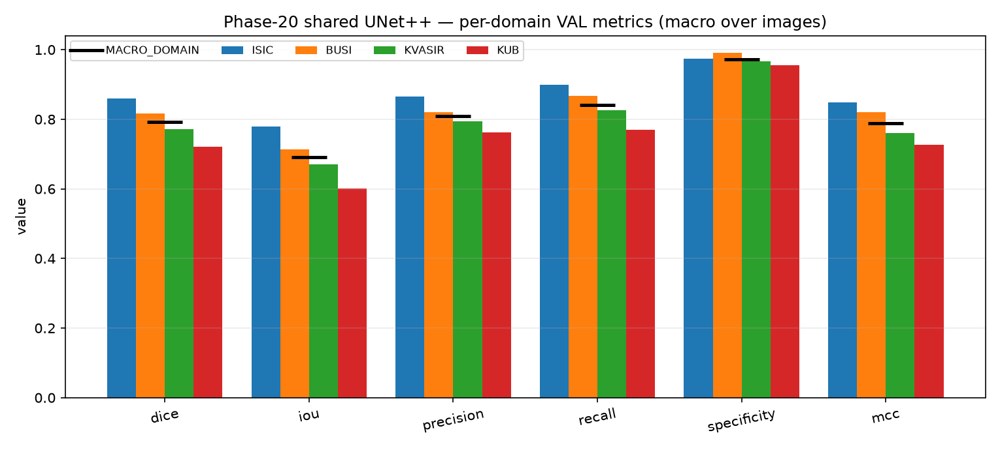

**confusion** — `reports\figures\phase20_multidomain_baseline\fig_confusion_row_normalized.png`

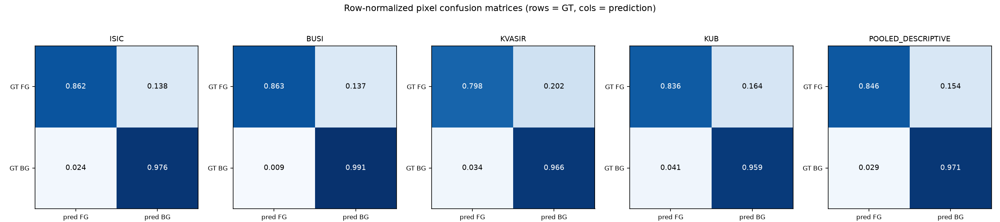

**boundary** — `reports\figures\phase20_multidomain_baseline\fig_boundary_metrics.png`

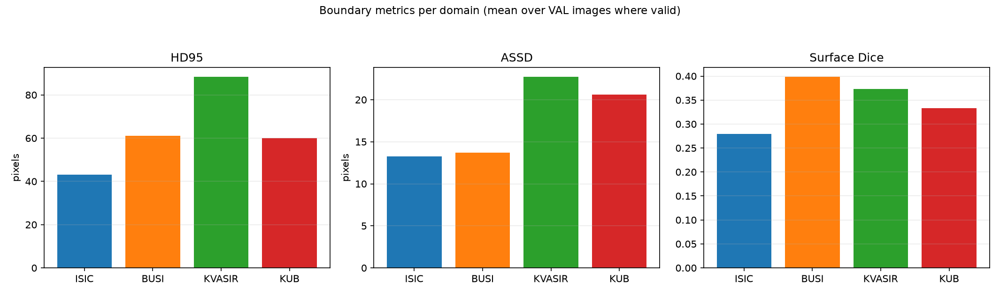

In [21]:
result_figs = pb.build_result_figures(domain_table, conf_json["matrices"], calib)
for name, path in result_figs.items():
    display(Markdown(f"**{name}** — `{path.relative_to(ROOT)}`"))
    display(Image(filename=str(path)))

## 31. KUB subgroup analysis

KUB is the reporting domain with known tiny-object difficulty. Subgroups come from valid
Phase-19 reporting metadata and are **reporting only** — they are never fed to the model and
are never treated as segmentation classes. Size strata use the frozen clean-v3 taxonomy
`kub_size_clean_v3_v1` (`component_ratio = component_pixels / (native_h * native_w)`,
FULL_FIELD only; ROI crops are `ROI_NOT_PRIMARY_BINNED`).

In [22]:
display(Markdown("**KUB overall + native-category subgroups (reporting only)**"))
display(pd.read_csv(TAB / "phase20_kub_subgroup_analysis.csv"))
display(Markdown("**KUB size-stratified performance (frozen clean-v3 taxonomy, descriptive)**"))
display(pd.read_csv(TAB / "phase20_kub_size_stratification.csv"))

**KUB overall + native-category subgroups (reporting only)**

,scope,subgroup,n,dice,iou,precision,recall,hd95,empty_prediction_rate,role
0,KUB_ALL,KUB_ALL,280,0.720662,0.601896,0.761739,0.770180,59.982761,0.035714,REPORTING_ONLY
1,KUB_SUBGROUP,Bladder_Stone,144,0.692989,0.570693,0.701901,0.774819,57.605428,0.041667,REPORTING_ONLY
2,KUB_SUBGROUP,Kidney_Stone,112,0.752332,0.638072,0.850262,0.745573,61.238300,0.026786,REPORTING_ONLY
3,KUB_SUBGROUP,Ureteric_Stone,24,0.738911,0.620290,0.701248,0.857178,68.296599,0.041667,REPORTING_ONLY


**KUB size-stratified performance (frozen clean-v3 taxonomy, descriptive)**

,stratum,n,dice,iou,median_component_ratio,taxonomy_id,role
0,TINY,44,0.531395,0.423062,0.000095,kub_size_clean_v3_v1,REPORTING_ONLY__DESCRIPTIVE
1,SMALL,19,0.680591,0.551392,0.000195,kub_size_clean_v3_v1,REPORTING_ONLY__DESCRIPTIVE
2,MEDIUM,27,0.640754,0.516926,0.000553,kub_size_clean_v3_v1,REPORTING_ONLY__DESCRIPTIVE
3,LARGE,13,0.635866,0.531117,0.001763,kub_size_clean_v3_v1,REPORTING_ONLY__DESCRIPTIVE
4,ROI_NOT_PRIMARY_BINNED,177,0.790431,0.669933,NaN,kub_size_clean_v3_v1,REPORTING_ONLY__DESCRIPTIVE


## 32. 64-case detailed prediction gallery

**Selection is deterministic and prediction-independent**: within each domain, VAL samples
are sorted by `sample_id` and an evenly spaced set of 16 indices is taken — 16 per domain,
**64 cases total**. The rule depends only on the manifest, so the same 64 sample IDs can be
reused in Phase 21 for a like-for-like comparison. Nothing is cherry-picked.

Each case shows 9 panels: A native image, B GT mask, C GT contour, D model input,
E probability map, F thresholded prediction, G TP/FP/FN error map, H prediction overlay,
I GT-vs-prediction contour overlay — plus per-case Dice / IoU / precision / recall.

Pages are paginated 4 cases per page so no panel becomes unreadable.

In [23]:
sel = pd.read_csv(TAB / "phase20_gallery_selection.csv")
print("cases selected:", len(sel),
      "| per domain:", {k: int(v) for k, v in sel.groupby("dataset").size().items()})
print("selection rule:", sel["selection_rule"].iloc[0],
      "| prediction-dependent:", bool(sel["prediction_dependent"].any()))
display(sel.groupby("dataset")["sample_id"].apply(list).to_frame("selected sample_ids"))
vis = jload(AUD / "phase20_visualization_evidence.json")
assert len(sel) == 64

cases selected: 64 | per domain: {'BUSI': 16, 'ISIC': 16, 'KUB': 16, 'KVASIR': 16}
selection rule: sorted_by_sample_id_evenly_spaced | prediction-dependent: False


,selected sample_ids
dataset,
BUSI,"[07451d37507d75a0456b73bc793517cc, 20637be7dac..."
ISIC,"[0012a4db87568a44b326db45138d2147, 1383f297ca1..."
KUB,"[00849cbfea1e926cc0bf0443c9a57ac0, 0e9913d7acb..."
KVASIR,"[0d740cab6154fe94c64c37dc141c59a1, 26565ddc097..."


**Gallery page 1** — `reports\figures\phase20_multidomain_baseline\gallery_page_01.png`

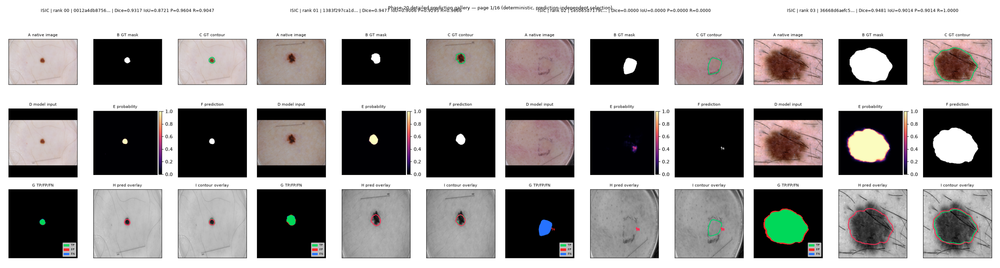

**Gallery page 2** — `reports\figures\phase20_multidomain_baseline\gallery_page_02.png`

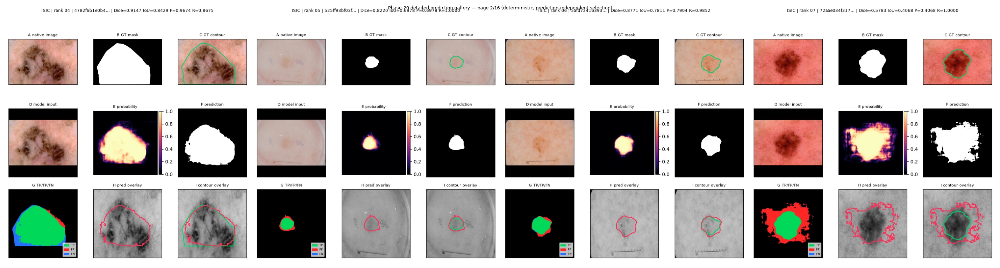

**Gallery page 3** — `reports\figures\phase20_multidomain_baseline\gallery_page_03.png`

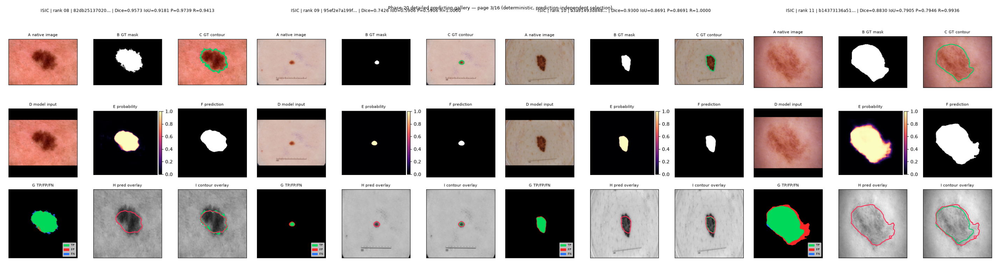

**Gallery page 4** — `reports\figures\phase20_multidomain_baseline\gallery_page_04.png`

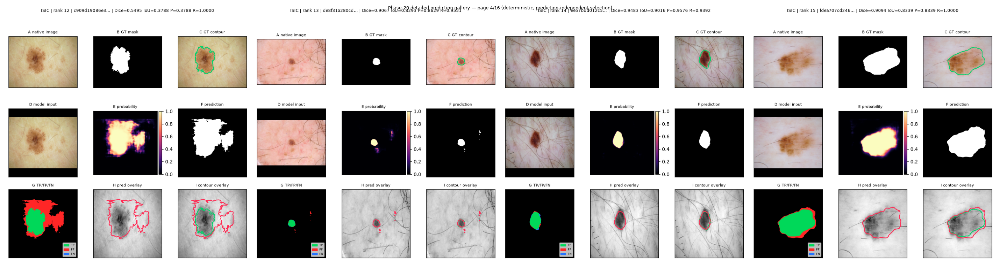

**Gallery page 5** — `reports\figures\phase20_multidomain_baseline\gallery_page_05.png`

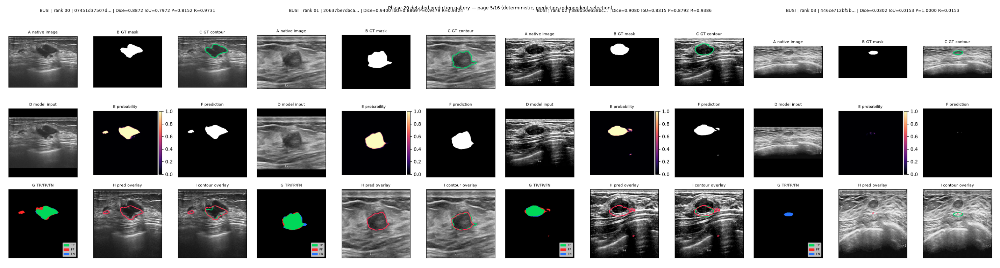

**Gallery page 6** — `reports\figures\phase20_multidomain_baseline\gallery_page_06.png`

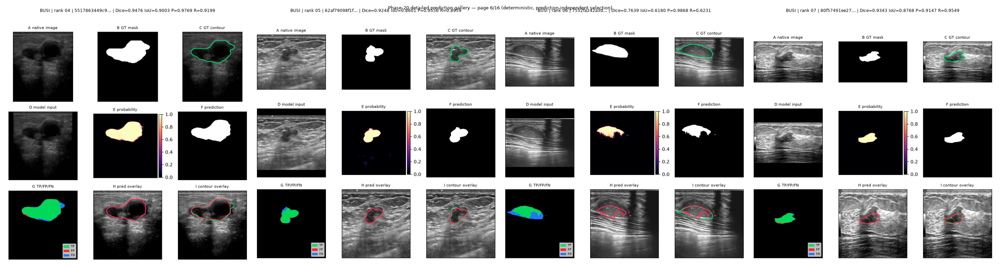

**Gallery page 7** — `reports\figures\phase20_multidomain_baseline\gallery_page_07.png`

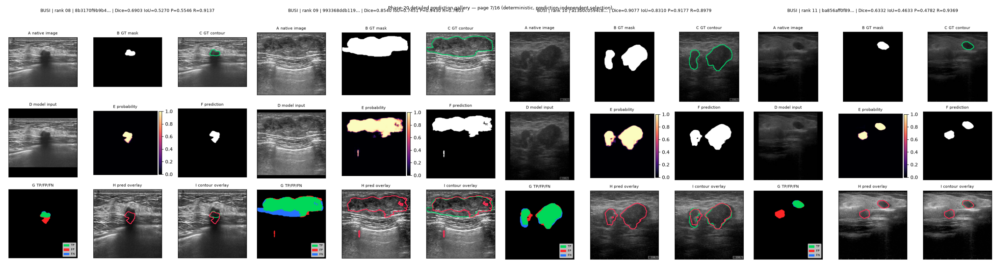

**Gallery page 8** — `reports\figures\phase20_multidomain_baseline\gallery_page_08.png`

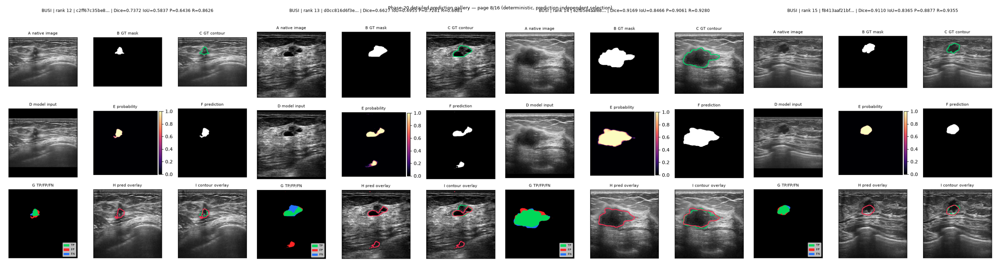

**Gallery page 9** — `reports\figures\phase20_multidomain_baseline\gallery_page_09.png`

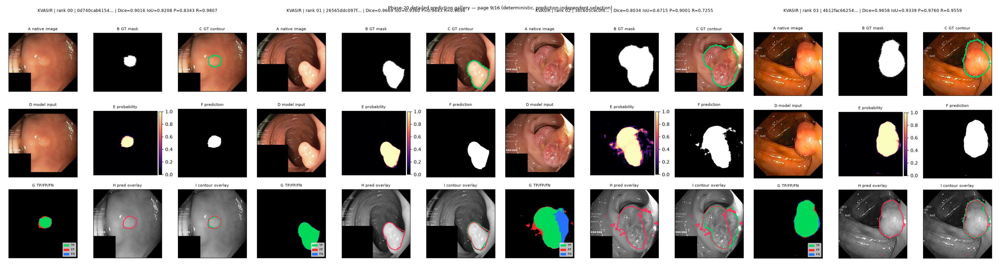

**Gallery page 10** — `reports\figures\phase20_multidomain_baseline\gallery_page_10.png`

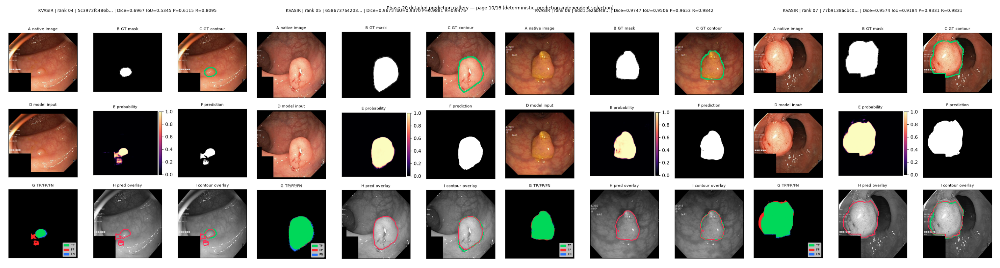

**Gallery page 11** — `reports\figures\phase20_multidomain_baseline\gallery_page_11.png`

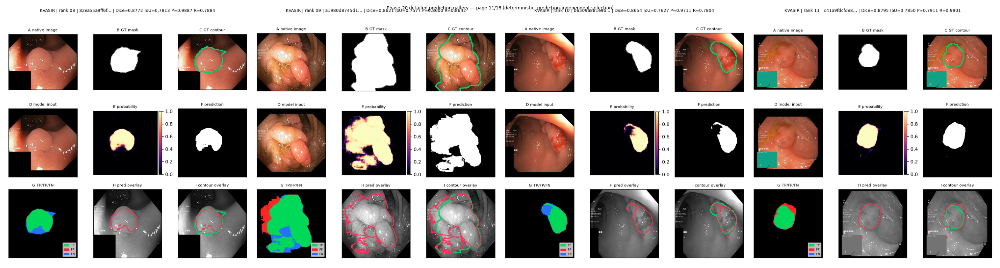

**Gallery page 12** — `reports\figures\phase20_multidomain_baseline\gallery_page_12.png`

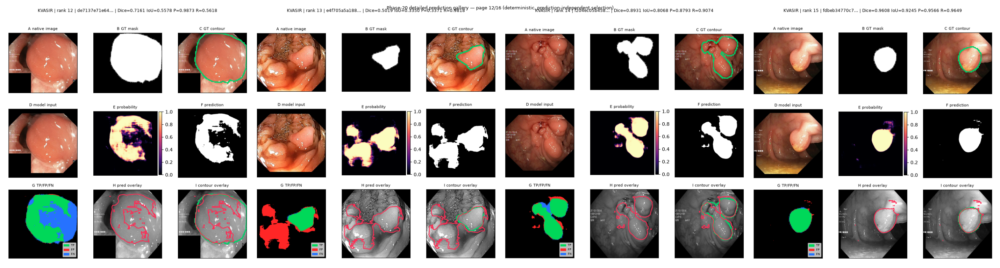

**Gallery page 13** — `reports\figures\phase20_multidomain_baseline\gallery_page_13.png`

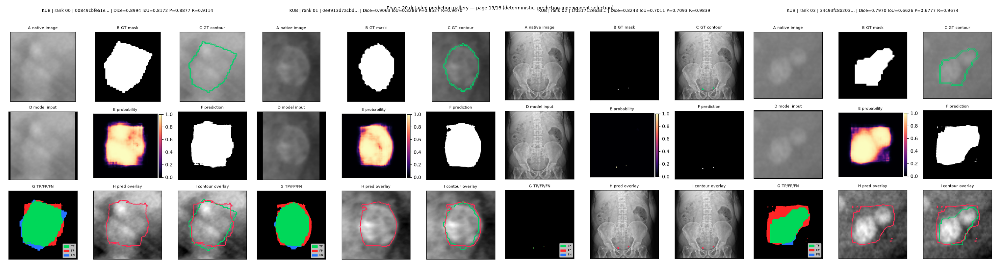

**Gallery page 14** — `reports\figures\phase20_multidomain_baseline\gallery_page_14.png`

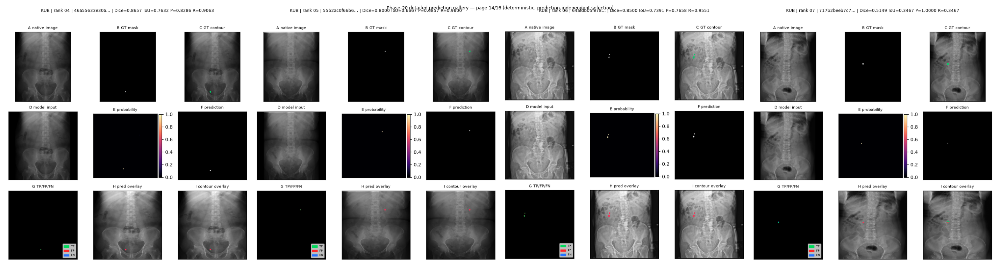

**Gallery page 15** — `reports\figures\phase20_multidomain_baseline\gallery_page_15.png`

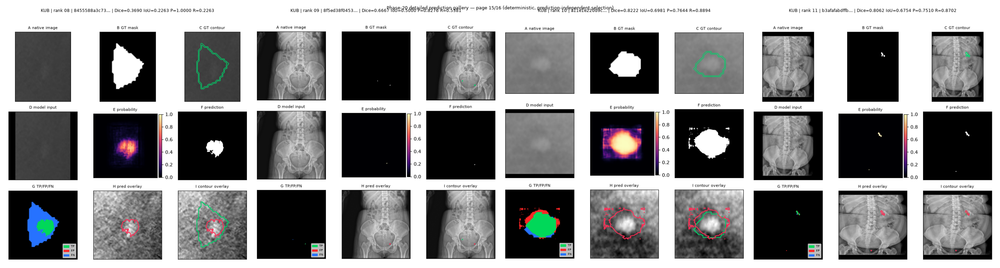

**Gallery page 16** — `reports\figures\phase20_multidomain_baseline\gallery_page_16.png`

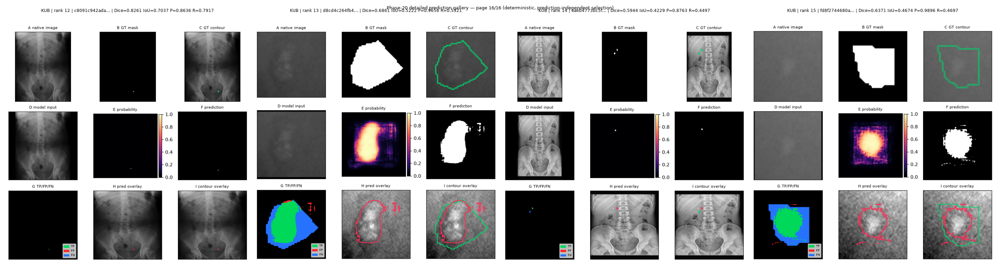

In [24]:
for i, page in enumerate(sorted(FIG.glob("gallery_page_*.png"))):
    display(Markdown(f"**Gallery page {i+1}** — `{page.relative_to(ROOT)}`"))
    display(Image(filename=str(page)))

## 33. Success / failure analysis

Failure evidence is shown alongside success evidence. This analysis is **descriptive** and
does not alter the frozen checkpoint.

**dice_distribution** — `reports/figures/phase20_multidomain_baseline/fig_dice_distribution_by_domain.png`

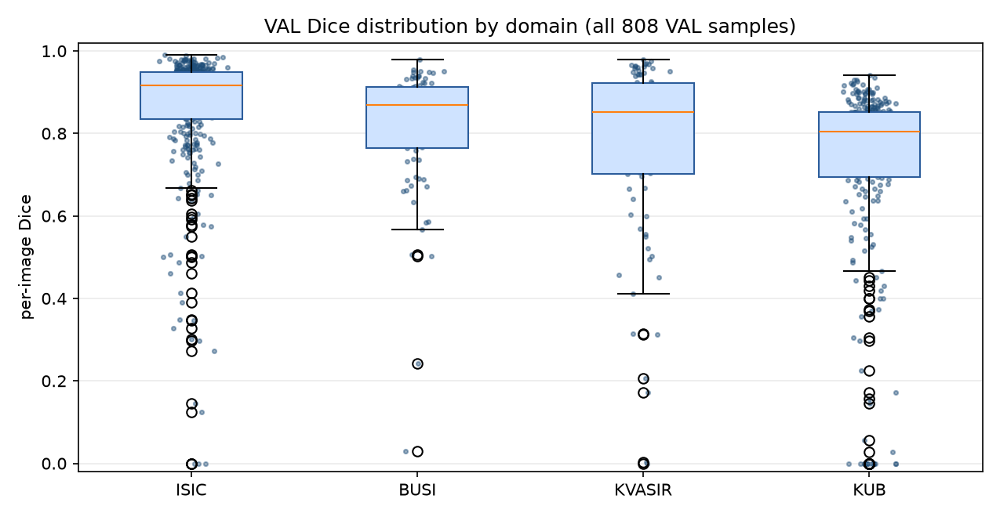

**low_performing** — `reports/figures/phase20_multidomain_baseline/fig_low_performing_cases.png`

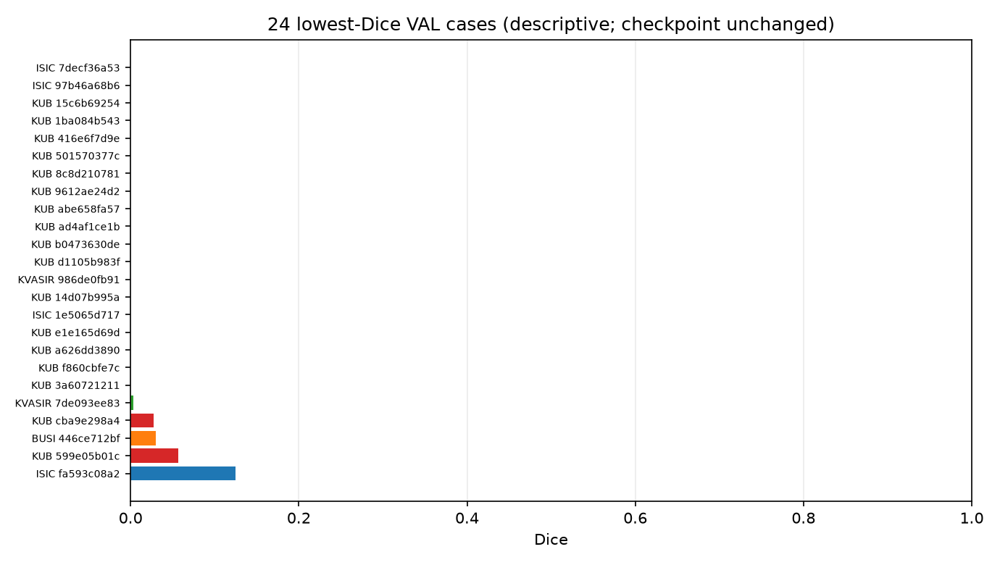

**fp_fn_dominant** — `reports/figures/phase20_multidomain_baseline/fig_fp_fn_dominant.png`

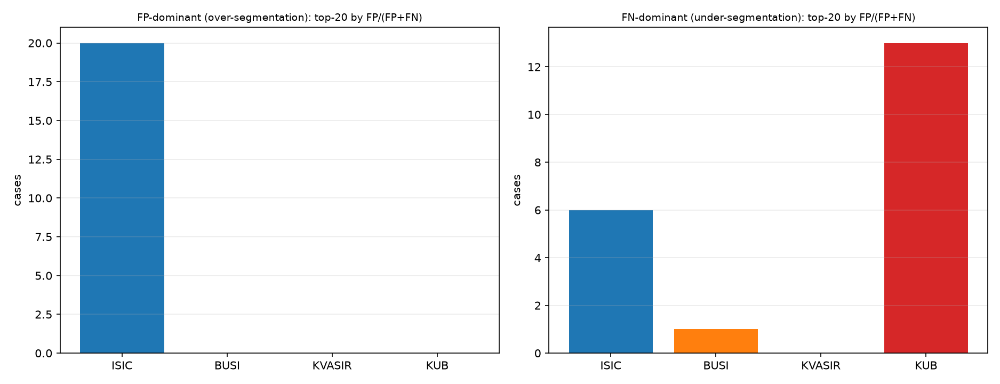

**empty_cases** — `reports/figures/phase20_multidomain_baseline/fig_empty_cases.png`

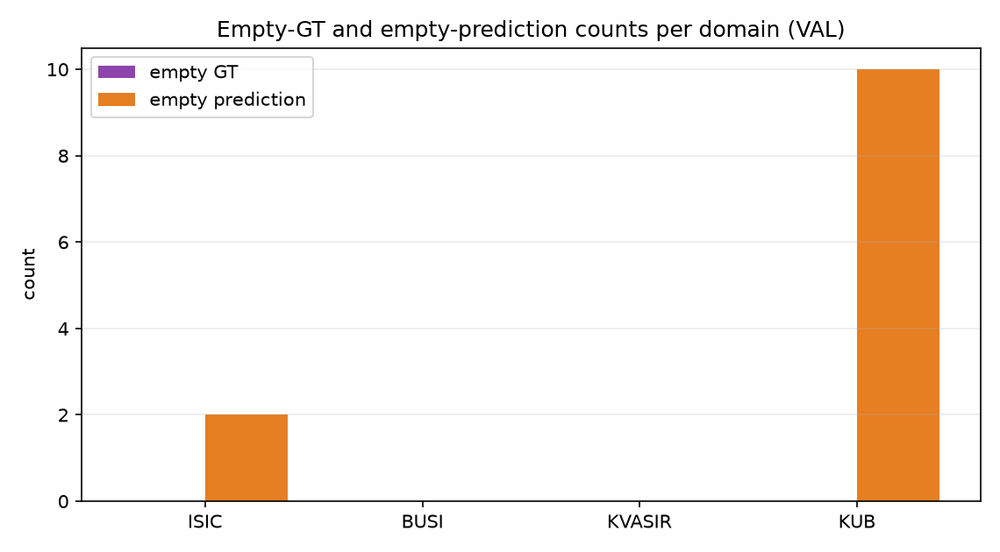

**Per-domain Dice quantiles**

,count,mean,std,min,25%,50%,75%,max
dataset,,,,,,,,
BUSI,84.0,0.816303,0.155085,3.020768e-02,0.765469,0.869379,0.911809,0.978269
ISIC,357.0,0.860074,0.159027,0.000000e+00,0.835013,0.917243,0.948927,0.991045
KUB,280.0,0.720662,0.229855,0.000000e+00,0.694376,0.803720,0.852574,0.941464
KVASIR,87.0,0.771001,0.220329,2.285662e-12,0.702437,0.851350,0.923058,0.979491


**Domain-specific failure patterns: empty predictions and FP/FN balance**

,n,empty_prediction,empty_gt,mean_fp_ratio,dice_lt_0_5
dataset,,,,,
BUSI,84,0,0,0.598897,2
ISIC,357,2,0,0.615900,15
KUB,280,10,0,0.558800,35
KVASIR,87,0,0,0.533374,10


In [25]:
sf = jload(AUD / "phase20_visualization_evidence.json")["success_failure_figures"]
for name, rel in sf.items():
    display(Markdown(f"**{name}** — `{rel}`"))
    display(Image(filename=str(ROOT / rel)))

per_image = pd.read_csv(TAB / "phase20_per_image_val_metrics.csv")
display(Markdown("**Per-domain Dice quantiles**"))
display(per_image.groupby("dataset")["dice"].describe()[["count", "mean", "std", "min",
                                                         "25%", "50%", "75%", "max"]])
display(Markdown("**Domain-specific failure patterns: empty predictions and FP/FN balance**"))
fails = per_image.assign(
    fp_ratio=per_image["fp"] / (per_image["fp"] + per_image["fn"]).replace(0, np.nan)
).groupby("dataset").agg(
    n=("sample_id", "size"),
    empty_prediction=("pred_empty", "sum"),
    empty_gt=("gt_empty", "sum"),
    mean_fp_ratio=("fp_ratio", "mean"),
    dice_lt_0_5=("dice", lambda s: int((s < 0.5).sum())),
)
display(fails)

## 34. Artifact provenance

In [26]:
prov_paths = [
    "reports/audits/phase20_phase19_authority_binding.json",
    "reports/audits/phase20_entry_gate.json",
    "reports/audits/phase20_cross_domain_duplicate_audit.json",
    "reports/audits/phase20_legacy_baseline_selection_evidence.json",
    "reports/audits/phase20_baseline_architecture_freeze.json",
    "reports/audits/phase20_sampling_policy_audit.json",
    "reports/audits/phase20_shared_global_baseline_protocol.json",
    "reports/audits/phase20_pre_execution_check.json",
    "reports/audits/phase20_training_closure.json",
    "reports/audits/phase20_checkpoint_selection_replay.json",
    "reports/audits/phase20_val_evaluation.json",
    "reports/audits/phase20_prediction_manifest.json",
    "reports/audits/phase20_confusion_matrices.json",
    "reports/audits/phase20_visualization_evidence.json",
    "reports/audits/phase20_phase21_entry_criteria.json",
    "reports/tables/phase20_per_image_val_metrics.csv",
    "reports/tables/phase20_domain_performance.csv",
    "reports/tables/phase20_confusion_matrices.csv",
    "reports/tables/phase20_calibration_ranking.csv",
    "reports/tables/phase20_domain_bootstrap_ci.csv",
    "reports/tables/phase20_kub_subgroup_analysis.csv",
    "reports/tables/phase20_kub_size_stratification.csv",
    "reports/tables/phase20_gallery_selection.csv",
    "reports/tables/phase20_prediction_manifest.csv",
    f"experiments/{EXP_ID}/history.csv",
    f"checkpoints/{EXP_ID}/best.pt",
    f"checkpoints/{EXP_ID}/latest.pt",
]
display(pd.DataFrame([{"artifact": p, "sha256": sha256_file(ROOT / p)[:40] + "…",
                       "bytes": (ROOT / p).stat().st_size} for p in prov_paths]))

,artifact,sha256,bytes
0,reports/audits/phase20_phase19_authority_bindi...,591c13919d844781223390e00e4d594635ea40d4…,3707
1,reports/audits/phase20_entry_gate.json,c4805d8c63bccd84b4888ba5415c5a78668edac4…,7094
2,reports/audits/phase20_cross_domain_duplicate_...,4e3047c61f4edff82a3aa3549e06f6f7db55ec5b…,4784
3,reports/audits/phase20_legacy_baseline_selecti...,1c3fbbe18449275704a79faaa29e72475ee85e6c…,12324
4,reports/audits/phase20_baseline_architecture_f...,aed29d3018abcae01501ceb3beb1719788fc61cb…,2237
5,reports/audits/phase20_sampling_policy_audit.json,69134c1c5811a363c484d37a41d84c65577993ab…,2196
6,reports/audits/phase20_shared_global_baseline_...,b74f1f9f429adbce374f0306180943b9f373f872…,8730
7,reports/audits/phase20_pre_execution_check.json,dc3d31f2cf8d67f0e64125c34e4ba68ea68eb6a8…,4879
8,reports/audits/phase20_training_closure.json,b7aaff2ba4a81278b597262f08eee96ddfcab112…,2387
9,reports/audits/phase20_checkpoint_selection_re...,8be41421b7110cf9b989c3efc6523bcb90fb9965…,11502


## 35. Known limitations

1. **Single seed.** One run, seed 42. Three-seed reproducibility belongs to Phase 29.
2. **No architecture comparison in this phase.** UNet++ was frozen from prior evidence; it
   is not compared here against U-Net / Attention U-Net / DeepLabV3+ on the four-domain pool.
3. **Operational input contract.** 3-channel input is a Phase-20 baseline choice, not the
   final Phase-24 architecture policy.
4. **Resolution frozen without a search.** 512 px was chosen prospectively from prior evidence
   and feasibility, not tuned.
5. **Boundary metrics are in pixels.** No physical pixel-spacing metadata exists, so HD95 /
   ASSD / surface Dice are not in millimetres.
6. **Calibration and ranking metrics use a deterministic pixel subsample**
   (stride 4), not every pixel.
7. **Pooled metrics are descriptive.** Macro-domain is the scientific summary.
8. **No TEST and no external validation.** Phase 39 owns the final TEST evaluation.
9. **Domain-balanced sampling changes the effective TRAIN distribution** (each domain ~25%),
   which is intentional but means epoch composition is not the raw manifest composition.
10. **Cross-domain near-duplicate detection used the approved 64-bit pHash** with the frozen
    Hamming <= 6 candidate threshold; pairs at 1-6 are reported, not adjudicated pixel-by-pixel.

## 36. Comparison to LEGACY prior values (historical, non-current)

The values below are context for why UNet++ was chosen. They are
**`LEGACY_PRIOR_EVIDENCE__NOT_CURRENT_PHASE20_RESULT`**: different splits, different
domain sets, and in the legacy multi-domain case a tuned threshold. They must **not** be read
as a Phase-20 benchmark and Phase-20 numbers must not be read as an improvement over them.

In [27]:
legacy = jload(AUD / "phase20_legacy_baseline_selection_evidence.json")
display(Markdown("**Same-repository clean-v3 KUB-only conventional comparison (historical)**"))
display(pd.DataFrame(legacy["same_repository_clean_v3_conventional_comparison"]["results"])[
    ["architecture", "best_epoch", "best_val_macro_dice", "stop_reason"]])
display(Markdown("**Legacy three-domain shared baselines (historical, superseded pipeline)**"))
legacy_rows = []
for p in legacy["legacy_projects"]:
    if p.get("historical_validation_result", {}).get("U-Net"):
        for model, vals in p["historical_validation_result"].items():
            if isinstance(vals, dict) and "dice" in vals:
                legacy_rows.append({"project": p["project"], "model": model,
                                    "dice": vals["dice"], "iou": vals.get("iou"),
                                    "domains": p["domain_count"],
                                    "includes_kub": p["includes_kub"]})
display(pd.DataFrame(legacy_rows))
display(Markdown(f"**Phase-20 (current, clean-v3, four domains, threshold 0.5, macro over images)**"))
display(domain_table[["row_type", "dataset", "n", "dice", "iou"]])
display(Markdown("_Comparison boundary: Phase 20 is not intended to prove MedFiLM, and no "
                 "Phase-21 result exists yet. Historical values are context only._"))

**Same-repository clean-v3 KUB-only conventional comparison (historical)**

,architecture,best_epoch,best_val_macro_dice,stop_reason
0,U-Net,44,0.740613,EARLY_STOP
1,Attention U-Net,54,0.752513,EARLY_STOP
2,UNet++,70,0.764160,EARLY_STOP
3,"DeepLabV3+ (ResNet-50, no pretrained weights)",52,0.750914,EARLY_STOP


**Legacy three-domain shared baselines (historical, superseded pipeline)**

,project,model,dice,iou,domains,includes_kub
0,final/medfilm_seg,U-Net,0.845300,0.732100,3,False
1,final/medfilm_seg,Attention U-Net,0.848794,0.737309,3,False
2,final/medfilm_seg,MedFiLM-Seg,0.866204,0.763986,3,False
3,final/medfilm_seg,MedFiLM-Seg Calibrated,0.871870,0.772845,3,False


**Phase-20 (current, clean-v3, four domains, threshold 0.5, macro over images)**

,row_type,dataset,n,dice,iou
0,DOMAIN,ISIC,357,0.860074,0.779969
1,DOMAIN,BUSI,84,0.816303,0.712567
2,DOMAIN,KVASIR,87,0.771001,0.669674
3,DOMAIN,KUB,280,0.720662,0.601896
4,MACRO_DOMAIN,MACRO_DOMAIN,808,0.792010,0.691026
5,POOLED_DESCRIPTIVE,POOLED_DESCRIPTIVE,808,0.841217,0.725948


_Comparison boundary: Phase 20 is not intended to prove MedFiLM, and no Phase-21 result exists yet. Historical values are context only._

## 37. Phase-21 entry criteria (prospective)

In [28]:
p21 = jload(AUD / "phase20_phase21_entry_criteria.json")
display(pd.DataFrame(p21["criteria"])[["id", "criterion", "met", "observed"]])
print("all criteria met:", p21["all_criteria_met"])
print("Phase 21 status:", p21["status"])
print("Phase 21 started:", p21["phase21_started"],
      "| authorization required:", p21["authorization_required"])
assert p21["phase21_started"] is False

,id,criterion,met,observed
0,P21-1,Phase-20 training naturally terminated,True,EARLY_STOPPING_PATIENCE
1,P21-2,checkpoint-selection replay PASS,True,PHASE20_CHECKPOINT_SELECTION_REPLAY_PASS
2,P21-3,all four domains evaluated,True,"[BUSI, ISIC, KUB, KVASIR]"
3,P21-4,macro-domain score available,True,0.79201
4,P21-5,per-domain scores available for every domain,True,4/4
5,P21-6,prediction artifacts persisted,True,808
6,P21-7,complete notebook executed,True,notebooks\phasewise\phase_20_multidomain_basel...
7,P21-8,64 deterministic cases available,True,64
8,P21-9,TEST reads = 0,True,"{'test_image_reads': 0, 'test_mask_reads': 0, ..."
9,P21-10,architecture/input/training artifacts SHA-bound,True,15


all criteria met: True
Phase 21 status: NOT_STARTED__AWAITING_SUPERVISOR_AUTHORIZATION
Phase 21 started: False | authorization required: True


## 38. TEST lock

In [29]:
from src.utils.test_lock import verify_test_lock

lock = verify_test_lock(str(ROOT))
display(pd.DataFrame([
    {"item": "manifest_version", "value": lock["manifest_version"]},
    {"item": "test_sample_count", "value": lock["test_sample_count"]},
    {"item": "frozen sha256", "value": lock["full_test_sha256"][:40] + "…"},
    {"item": "observed sha256", "value": sha256_file(ROOT / "manifests/test.csv")[:40] + "…"},
    {"item": "test_image_reads", "value": closure["test_reads"]["test_image_reads"]},
    {"item": "test_mask_reads", "value": closure["test_reads"]["test_mask_reads"]},
    {"item": "test_inference", "value": closure["test_reads"]["test_inference"]},
    {"item": "test_visualization", "value": closure["test_reads"]["test_visualization"]},
    {"item": "final TEST evaluation phase", "value": 39},
]))
assert sha256_file(ROOT / "manifests/test.csv") == lock["full_test_sha256"]
assert all(v == 0 for v in closure["test_reads"].values())

,item,value
0,manifest_version,phase4_v2
1,test_sample_count,1683
2,frozen sha256,9361eba61c91c034a9aa4988a4df229bba591a5c…
3,observed sha256,9361eba61c91c034a9aa4988a4df229bba591a5c…
4,test_image_reads,0
5,test_mask_reads,0
6,test_inference,0
7,test_visualization,0
8,final TEST evaluation phase,39


## 39. Terminal state

In [30]:
state = {
    "phase_19": "COMPLETE / HARMONIZATION PREPARATION",
    "phase_20": "SHARED GLOBAL BASELINE COMPLETE",
    "phase_20_experiment": EXP_ID,
    "architecture": "UNet++ (shared, image-only, no FiLM, no regional module)",
    "best_epoch": closure["best_epoch"],
    "best_macro_domain_dice": closure["best_macro_domain_dice"],
    "stop_reason": closure["stop_reason"],
    "checkpoint_replay": replay["verdict"],
    "phase_21": "ELIGIBLE__NOT_STARTED",
    "test": "CLOSED",
}
display(pd.DataFrame(sorted(state.items()), columns=["governance item", "state"]))

display(Markdown("### Final assertions"))
assert protocol["status"] == "PHASE20_PROTOCOL_FROZEN__AWAITING_EXECUTION"
assert freeze["current_phase20_results_used_for_selection"] is False
assert dup["n_blocking_pairs"] == 0
assert pre["all_checks_passed"] is True
assert replay["verdict"] == "PHASE20_CHECKPOINT_SELECTION_REPLAY_PASS"
assert len(per_image) == 808
assert len(sel) == 64
assert closure["independent_duplicate_runs"] == 0
assert all(v == 0 for v in closure["test_reads"].values())
assert p21["phase21_started"] is False
print("✓ All Phase-20 assertions passed.")
print("TERMINAL STATE: PHASE20_SHARED_GLOBAL_BASELINE_COMPLETE__PHASE21_ELIGIBLE_NOT_STARTED")

,governance item,state
0,architecture,"UNet++ (shared, image-only, no FiLM, no region..."
1,best_epoch,55
2,best_macro_domain_dice,0.792007
3,checkpoint_replay,PHASE20_CHECKPOINT_SELECTION_REPLAY_PASS
4,phase_19,COMPLETE / HARMONIZATION PREPARATION
5,phase_20,SHARED GLOBAL BASELINE COMPLETE
6,phase_20_experiment,phase20_shared_unetpp_fourdomain_seed42_clean_v3
7,phase_21,ELIGIBLE__NOT_STARTED
8,stop_reason,EARLY_STOPPING_PATIENCE
9,test,CLOSED


### Final assertions

✓ All Phase-20 assertions passed.
TERMINAL STATE: PHASE20_SHARED_GLOBAL_BASELINE_COMPLETE__PHASE21_ELIGIBLE_NOT_STARTED
